# BÀI TẬP LỚN: NỀN TẢNG LẬP TRÌNH CHO PHÂN TÍCH VÀ TRỰC QUAN DỮ LIỆU
## CHỦ ĐỀ DỮ LIỆU ẢNH (IMAGE CLASSIFICATION)
# Intel Image Classification: Từ Baseline CNN đến Fine-tuning, ViT và Zero-shot CLIP

Notebook này giải quyết bài toán phân loại 6 lớp cảnh quan (`buildings`, `forest`, `glacier`, `mountain`, `sea`, `street`) trên bộ dữ liệu **Intel Image Classification** (17.034 ảnh). Thay vì chỉ chạy một mô hình đơn lẻ, bài viết tập trung vào **so sánh có kiểm soát** giữa nhiều hướng tiếp cận để trả lời các câu hỏi thực tế:

1. **Khám phá dữ liệu (EDA):** Phân tích phân bố lớp, kích thước ảnh, phổ màu RGB và t-SNE để dự đoán trước các cặp lớp dễ nhầm lẫn (`glacier` $\leftrightarrow$ `mountain`, `street` $\leftrightarrow$ `buildings`).
2. **Pipeline tiền xử lý chuẩn theo mô hình:** Tách Stratified Split (85% Train / 15% Val, độc lập với 3.000 ảnh Test); dùng đúng chuẩn `150x150` cho mô hình train từ đầu và `224x224` (ImageNet mean/std) cho mô hình pretrained.
3. **Đối chiếu các chiến lược & kiến trúc mô hình:**
   - **Train from scratch:** `SimpleBaselineCNN` (0.42M) và `ResNet-18` (11.18M).
   - **Transfer Learning trên cùng kiến trúc ResNet-18:** `Linear Probe` (đóng băng backbone) vs `Fine-tuning` (mở khóa `layer4 + fc` với Differential LR).
   - **Kiến trúc hiện đại:** `ViT-B/16` (Vision Transformer) để so sánh cơ chế Self-Attention toàn cục với CNN.
   - **Vision–Language Foundation Model:** `CLIP ViT-B/32` ở chế độ **Zero-shot** (không train trên tập nhãn, dùng text prompt).
4. **Đánh giá góc độ Engineering & XAI:** Đo thêm thời gian train, Peak VRAM và tốc độ suy luận (ms/ảnh) bên cạnh Accuracy/F1; phân tích lỗi chéo giữa các mô hình và trực quan hóa vùng chú ý bằng **Grad-CAM**.

# PHẦN I: KHÁM PHÁ DỮ LIỆU & PHÂN TÍCH ĐẶC TRƯNG THỊ GIÁC (EDA)
Phần này cung cấp cái nhìn định lượng và định tính về cấu trúc, chất lượng ảnh, phân bố không gian màu sắc và các đặc trưng hình thái học trước khi bước vào xây dựng mô hình.

## 1. Chuẩn bị Dữ liệu và Kiểm tra Tính Toàn vẹn (Data Ingestion & Integrity)

### 1.1 Cài đặt và Nạp Thư viện Cần thiết

Cài đặt các gói phụ thuộc cần thiết.

In [1]:
# Cài đặt các thư viện phụ thuộc (nếu đang chạy trên Google Colab / Kaggle / Local mới)
%pip install -q kagglehub torch torchvision opencv-python-headless scikit-learn seaborn matplotlib pandas numpy pillow


In [2]:
import os
import sys
import time
import math
import copy
import glob
import random
import shutil
import collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageStat, ImageFilter, ImageEnhance
import cv2

# Thư viện Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Thư viện PyTorch & Torchvision
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

# 1. Thiết lập Seed để tăng tính tái lập giữa các lần chạy
RANDOM_SEED = 42

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(RANDOM_SEED)

# 2. Thiết bị tính toán
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 3. Cấu hình hiển thị biểu đồ
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 100

print(f"Python  : {sys.version.split()[0]}")
print(f"PyTorch : {torch.__version__}")
print(f"Device  : {device}")
if torch.cuda.is_available():
    print(f"GPU     : {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB)")
else:
    print("Lưu ý: Đang chạy CPU (nên bật GPU T4 trên Colab để train nhanh hơn).")

Python  : 3.13.16
PyTorch : 2.14.1+cu130
Device  : cuda
GPU     : Tesla T4 (15.64 GB)


### 1.2 Tải và thiết lập nguồn dữ liệu từ Kaggle

Tập dữ liệu sử dụng: [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification).

Notebook sử dụng thư viện `kagglehub` để tải dữ liệu khi chưa tìm thấy bản dữ liệu cục bộ. Cách tiếp cận này giúp đơn giản hóa việc thiết lập trên các môi trường như Google Colab, Kaggle Notebook và máy tính cá nhân, miễn là môi trường có thể truy cập Kaggle và đáp ứng các yêu cầu tải dữ liệu.

Hàm `resolve_intel_dataset_paths()` tự động tìm các thư mục `seg_train`, `seg_test` và `seg_pred` trong những vị trí dữ liệu cục bộ phổ biến. Nếu không tìm thấy dữ liệu cục bộ, notebook sẽ tải dataset thông qua `kagglehub`, sau đó xác định đường dẫn đến từng phân vùng để sử dụng ở các bước tiếp theo.

In [3]:

import kagglehub
from pathlib import Path


def resolve_intel_dataset_paths():
    local_candidates = [
        Path("data"),
        Path("data/intel_images"),
        Path("seg_train"),
    ]

    split_names = ("seg_train", "seg_test", "seg_pred")
    dataset_root = None

    # Tìm dữ liệu đã có trên máy
    for candidate in local_candidates:
        if not candidate.exists():
            continue

        # Nếu candidate chính là thư mục seg_train,
        # thư mục gốc dữ liệu sẽ là thư mục cha của nó.
        search_root = (
            candidate.parent
            if candidate.name == "seg_train" and candidate.is_dir()
            else candidate
        )

        found_train = (
            search_root
            if search_root.name == "seg_train" and search_root.is_dir()
            else next(
                (
                    path for path in search_root.rglob("seg_train")
                    if path.is_dir()
                ),
                None,
            )
        )

        if found_train is not None:
            dataset_root = found_train.parent
            print(
                "Tìm thấy dữ liệu cục bộ tại: "
                f"{dataset_root.resolve()}"
            )
            break

    # Tải dữ liệu nếu chưa tìm thấy bản cục bộ
    if dataset_root is None:
        print("Không tìm thấy dữ liệu cục bộ. Đang tải từ Kaggle...")
        cache_path = kagglehub.dataset_download(
            "puneet6060/intel-image-classification"
        )
        dataset_root = Path(cache_path)
        print(f"Dữ liệu được lưu tại: {dataset_root.resolve()}")

    # Tìm thư mục phân vùng trong thư mục gốc
    def find_split(name):
        if dataset_root.name == name and dataset_root.is_dir():
            return dataset_root

        candidates = sorted(
            (path for path in dataset_root.rglob(name) if path.is_dir()),
            key=lambda path: len(path.parts),
            reverse=True,
        )

        return candidates[0] if candidates else None

    train_dir = find_split("seg_train")
    test_dir = find_split("seg_test")
    pred_dir = find_split("seg_pred")

    # Kiểm tra các phân vùng cần thiết
    missing = [
        name
        for name, path in (
            ("seg_train", train_dir),
            ("seg_test", test_dir),
            ("seg_pred", pred_dir),
        )
        if path is None
    ]

    if missing:
        raise FileNotFoundError(
            "Không tìm thấy các thư mục dữ liệu: "
            + ", ".join(missing)
            + f". Thư mục gốc đã kiểm tra: {dataset_root.resolve()}"
        )

    return train_dir, test_dir, pred_dir


TRAIN_DIR, TEST_DIR, PRED_DIR = resolve_intel_dataset_paths()

print("-" * 60)
print(f"Train : {TRAIN_DIR}")
print(f"Test  : {TEST_DIR}")
print(f"Pred  : {PRED_DIR}")


Không tìm thấy dữ liệu cục bộ. Đang tải từ Kaggle...
Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dữ liệu được lưu tại: /kaggle/input/intel-image-classification
------------------------------------------------------------
Train : /kaggle/input/intel-image-classification/seg_train/seg_train
Test  : /kaggle/input/intel-image-classification/seg_test/seg_test
Pred  : /kaggle/input/intel-image-classification/seg_pred/seg_pred


### 1.3 Kiểm tra tính toàn vẹn của tệp ảnh (Data Sanity Check)

Trước khi phân tích dữ liệu, nhóm kiểm tra các tệp ảnh trong tập Train và Test nhằm phát hiện những vấn đề có thể ảnh hưởng đến quá trình xử lý, bao gồm:

- Tệp ảnh bị hỏng hoặc không thể đọc.
- Tệp rỗng hoặc có định dạng không được hỗ trợ.
- Kích thước ảnh, tỷ lệ khung hình và số kênh màu không đồng nhất.

Hàm `PIL.Image.verify()` được sử dụng để kiểm tra sơ bộ tính toàn vẹn của tệp. Sau đó, ảnh được mở lại để trích xuất metadata như kích thước, số kênh màu, tỷ lệ khung hình và dung lượng tệp.

Kết quả kiểm tra giúp nhóm xác định số lượng ảnh đọc được, các tệp có lỗi và những khác biệt về đặc điểm ảnh cần lưu ý trong các bước tiền xử lý tiếp theo.

In [4]:

def audit_dataset_integrity(directory, split_name="Train"):
    records = []
    corrupted_files = []
    non_rgb_files = []

    supported_extensions = {".jpg", ".jpeg", ".png"}

    class_folders = sorted(
        d for d in directory.iterdir() if d.is_dir()
    )

    for cls_dir in class_folders:
        class_name = cls_dir.name

        img_paths = sorted(
            p for p in cls_dir.iterdir()
            if p.is_file() and p.suffix.lower() in supported_extensions
        )

        for p in img_paths:
            try:
                # Kiểm tra tệp rỗng trước khi đọc ảnh
                filesize = p.stat().st_size
                if filesize == 0:
                    raise ValueError("Tệp rỗng (0 byte)")

                # Kiểm tra sơ bộ cấu trúc tệp ảnh
                with Image.open(p) as img:
                    img.verify()

                # Mở lại ảnh để đọc metadata
                with Image.open(p) as img:
                    img.load()

                    w, h = img.size
                    mode = img.mode
                    channels = len(img.getbands())

                    record = {
                        "filepath": str(p),
                        "filename": p.name,
                        "split": split_name,
                        "class": class_name,
                        "width": w,
                        "height": h,
                        "mode": mode,
                        "channels": channels,
                        "is_rgb": mode == "RGB",
                        "aspect_ratio": round(w / h, 4) if h else None,
                        "filesize_kb": round(filesize / 1024, 2),
                    }

                    records.append(record)

                    if mode != "RGB":
                        non_rgb_files.append(
                            (str(p), mode, channels)
                        )

            except Exception as e:
                corrupted_files.append((str(p), str(e)))

    df_meta = pd.DataFrame(records)

    return df_meta, corrupted_files, non_rgb_files


print("Kiểm tra tính toàn vẹn của tập Train và Test...")

df_train_meta, corrupt_train, non_rgb_train = (
    audit_dataset_integrity(TRAIN_DIR, "Train")
)
df_test_meta, corrupt_test, non_rgb_test = (
    audit_dataset_integrity(TEST_DIR, "Test")
)

# Tổng hợp metadata của hai tập
df_meta = pd.concat(
    [df_train_meta, df_test_meta],
    ignore_index=True
)

print(f"Tổng số ảnh đọc được - Train: {len(df_train_meta):,}")
print(f"Tổng số ảnh đọc được - Test : {len(df_test_meta):,}")
print(f"Số tệp lỗi - Train          : {len(corrupt_train):,}")
print(f"Số tệp lỗi - Test           : {len(corrupt_test):,}")
print(f"Số ảnh không ở chế độ RGB   : {len(non_rgb_train) + len(non_rgb_test):,}")

if not df_meta.empty:
    print(f"Các chế độ ảnh phát hiện    : {sorted(df_meta['mode'].unique())}")
    print(f"Các số kênh màu phát hiện   : {sorted(df_meta['channels'].unique())}")


Kiểm tra tính toàn vẹn của tập Train và Test...
Tổng số ảnh đọc được - Train: 14,034
Tổng số ảnh đọc được - Test : 3,000
Số tệp lỗi - Train          : 0
Số tệp lỗi - Test           : 0
Số ảnh không ở chế độ RGB   : 0
Các chế độ ảnh phát hiện    : ['RGB']
Các số kênh màu phát hiện   : [np.int64(3)]


**Nhận xét:**

- **Tính toàn vẹn của tệp:** Không phát hiện tệp ảnh bị lỗi trong 14.034 ảnh thuộc tập Train và 3.000 ảnh thuộc tập Test. Các tệp đều được đọc thành công trong quá trình kiểm tra.
- **Kênh màu:** Toàn bộ ảnh được ghi nhận có 3 kênh màu RGB, không phát hiện ảnh grayscale hoặc ảnh RGBA. Điều này giúp thống nhất dữ liệu đầu vào và đơn giản hóa quá trình tiền xử lý trước khi chuyển ảnh thành tensor.

## 2. Phân bố nhãn và khảo sát thuộc tính không gian

### 2.1 Phân phối số lượng mẫu theo lớp (Train vs. Test)

Nhóm thống kê số lượng và tỷ lệ ảnh của từng lớp trên hai tập Train và Test nhằm đánh giá mức độ cân bằng của dữ liệu. Kết quả được trình bày bằng bảng thống kê và biểu đồ cột để thuận tiện so sánh phân bố giữa các lớp, đồng thời kiểm tra mức độ nhất quán giữa hai tập dữ liệu.

PHÂN PHỐI MẪU THEO LỚP


,Train,Test,Train_Pct (%),Test_Pct (%),Train/Test Ratio
class,,,,,
mountain,2512,525,17.90,17.50,4.78
glacier,2404,553,17.13,18.43,4.35
street,2382,501,16.97,16.70,4.75
sea,2274,510,16.20,17.00,4.46
forest,2271,474,16.18,15.80,4.79
buildings,2191,437,15.61,14.57,5.01


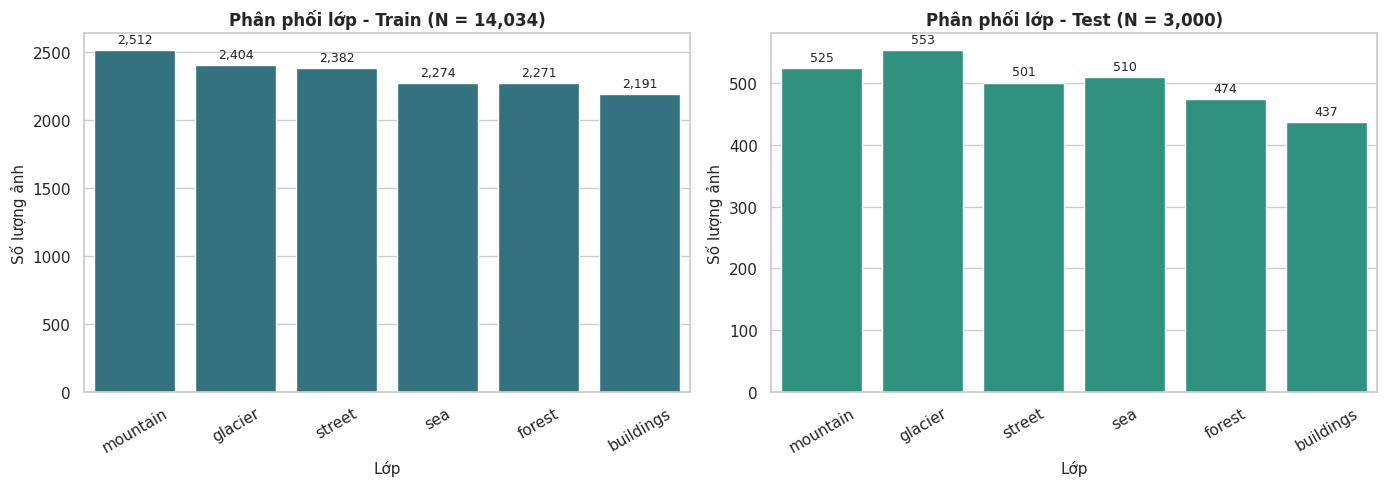

In [5]:

# Thống kê số lượng và tỷ lệ mẫu theo lớp
summary_train = df_train_meta["class"].value_counts()
summary_test = df_test_meta["class"].value_counts()

df_classes = pd.DataFrame({
    "Train": summary_train,
    "Test": summary_test,
}).fillna(0).astype(int)

df_classes["Train_Pct (%)"] = (
    df_classes["Train"] / df_classes["Train"].sum() * 100
).round(2)

df_classes["Test_Pct (%)"] = (
    df_classes["Test"] / df_classes["Test"].sum() * 100
).round(2)

df_classes["Train/Test Ratio"] = (
    df_classes["Train"] / df_classes["Test"].replace(0, np.nan)
).round(2)

df_classes = df_classes.sort_values("Train", ascending=False)

print("PHÂN PHỐI MẪU THEO LỚP")
display(df_classes)

# Trực quan hóa phân phối lớp
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_data = df_classes.reset_index(names="class")

# Tập Train
sns.barplot(
    data=plot_data,
    x="class",
    y="Train",
    order=df_classes.index.tolist(),
    color=sns.color_palette("crest", 6)[3],
    ax=axes[0],
)

axes[0].set_title(
    f"Phân phối lớp - Train (N = {df_classes['Train'].sum():,})",
    fontweight="bold",
)
axes[0].set_xlabel("Lớp")
axes[0].set_ylabel("Số lượng ảnh")
axes[0].tick_params(axis="x", rotation=30)

for p in axes[0].patches:
    height = int(p.get_height())
    axes[0].annotate(
        f"{height:,}",
        (p.get_x() + p.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 3),
        textcoords="offset points",
    )

# Tập Test
sns.barplot(
    data=plot_data,
    x="class",
    y="Test",
    order=df_classes.index.tolist(),
    color=sns.color_palette("viridis", 6)[3],
    ax=axes[1],
)

axes[1].set_title(
    f"Phân phối lớp - Test (N = {df_classes['Test'].sum():,})",
    fontweight="bold",
)
axes[1].set_xlabel("Lớp")
axes[1].set_ylabel("Số lượng ảnh")
axes[1].tick_params(axis="x", rotation=30)

for p in axes[1].patches:
    height = int(p.get_height())
    axes[1].annotate(
        f"{height:,}",
        (p.get_x() + p.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()


**Nhận xét:**
- **Độ cân bằng lớp:** Tập dữ liệu có phân phối số lượng ảnh tương đối đồng đều giữa các lớp:
  - Ở tập Train, số lượng ảnh mỗi lớp dao động từ 2.191 đến 2.512 ảnh. Lớp có nhiều ảnh nhất (mountain, 17,90%) chỉ gấp khoảng 1,15 lần lớp có ít ảnh nhất (buildings, 15,61%).
  - Ở tập Test, số lượng ảnh mỗi lớp nằm trong khoảng 437 đến 553 ảnh, tương ứng tỷ lệ từ 14,57% đến 18,43%.
- **Tỷ lệ phân chia Train/Test:** Số lượng mẫu ở tập Train gấp khoảng 4,35 đến 5,01 lần tập Test giữa các lớp, tương ứng tỷ lệ phân chia xấp xỉ 82% Train và 18% Test.
- **Ảnh hưởng đến quá trình huấn luyện và đánh giá:** Do số lượng mẫu giữa các lớp khá đồng đều nên không đòi hỏi các kỹ thuật xử lý mất cân bằng lớp đặc biệt. Có thể sử dụng Top-1 Accuracy và Macro F1-Score làm các chỉ số đánh giá chính, trong đó Accuracy phản ánh tỷ lệ dự đoán đúng tổng thể, còn Macro F1 giúp đánh giá hiệu năng trên từng lớp đồng đều hơn.

### 2.2 Trực quan hóa Mẫu Ảnh Đại diện theo Từng Lớp (Class Gallery)

Khảo sát trực quan một số ảnh ngẫu nhiên thuộc từng lớp để nhận diện ngữ cảnh hình ảnh, điều kiện chiếu sáng và đặc trưng cảnh vật đại diện.

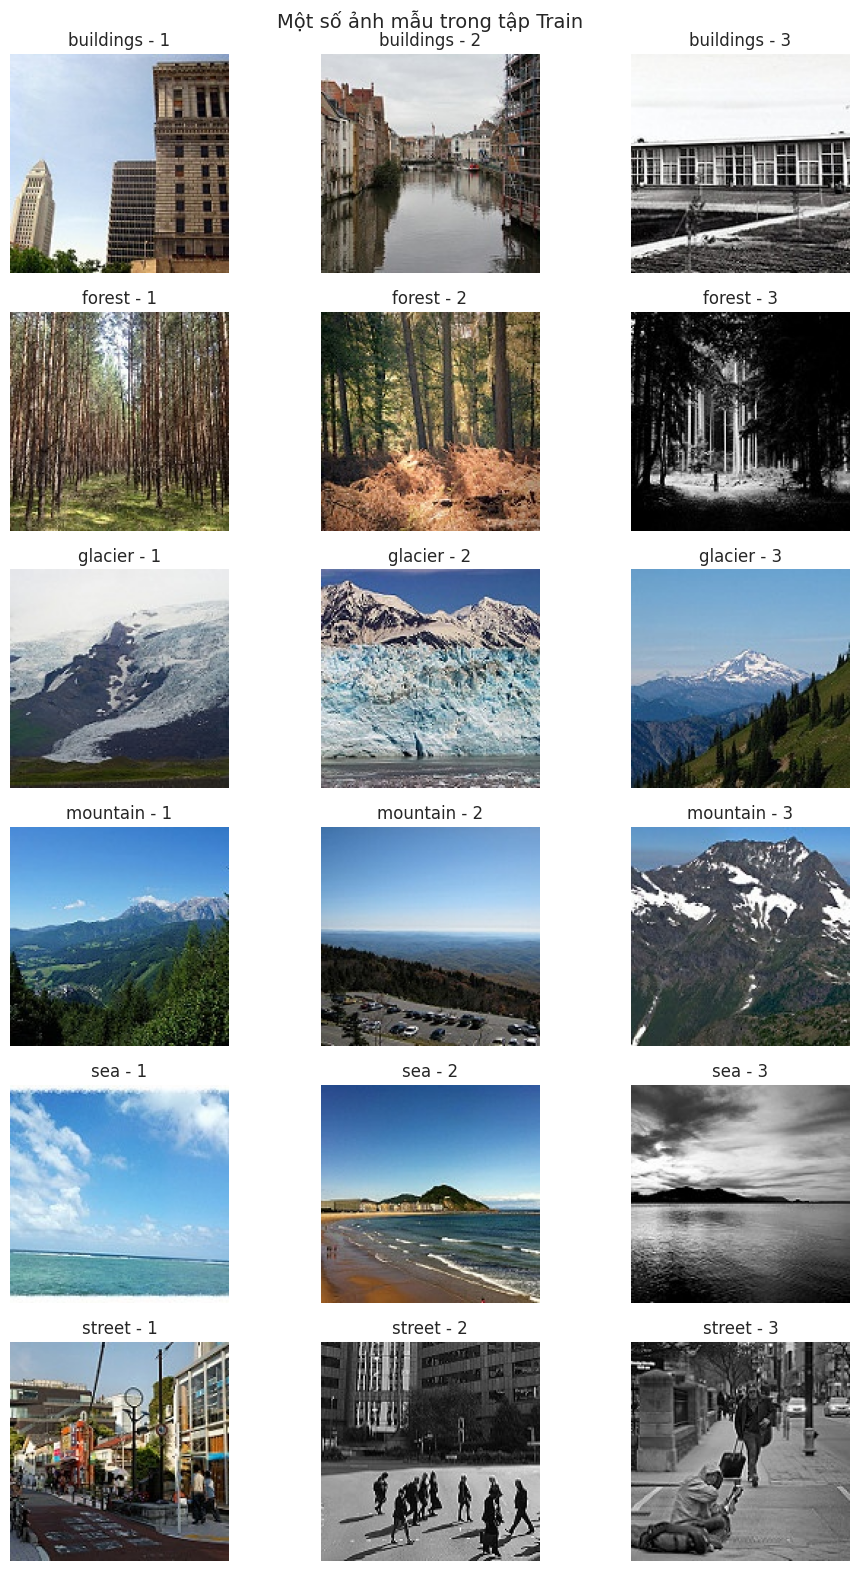

In [6]:
classes = sorted(df_train_meta['class'].unique())
num_samples = 3

fig, axes = plt.subplots(len(classes), num_samples, figsize=(10, 16))

for i, cls in enumerate(classes):
    samples = df_train_meta[df_train_meta['class'] == cls].sample(
        n=num_samples, random_state=RANDOM_SEED
    )

    for j, path in enumerate(samples['filepath']):
        with Image.open(path) as img:
            axes[i, j].imshow(img)

        axes[i, j].set_title(f'{cls} - {j + 1}')
        axes[i, j].axis('off')

plt.suptitle('Một số ảnh mẫu trong tập Train', fontsize=14)
plt.tight_layout()
plt.show()

**Nhận xét:**

Quan sát các ảnh mẫu cho thấy mỗi lớp có một số đặc điểm riêng:

- `buildings`: Thường xuất hiện hình ảnh các tòa nhà, cửa sổ và những cấu trúc nhân tạo.
- `forest`: Chủ yếu là cây cối, tán lá và các mảng màu xanh.
- `glacier`: Có nhiều vùng tuyết hoặc băng, với tông màu trắng và xanh lạnh.
- `mountain`: Đặc trưng bởi địa hình núi, sườn dốc và các khối đá, đôi khi có tuyết phủ.
- `sea`: Phần lớn là mặt biển và bầu trời, thường có đường chân trời tương đối rõ.
- `street`: Thường có mặt đường, các công trình hai bên và góc nhìn theo chiều sâu.

Nhìn chung, các lớp có những đặc điểm thị giác tương đối khác nhau, giúp mô hình dễ dàng phân biệt. Tuy nhiên, một số lớp vẫn có thể bị nhầm lẫn, chẳng hạn `glacier` và `mountain` khi cùng xuất hiện tuyết, hoặc `buildings` và `street` khi ảnh có cả đường phố lẫn các tòa nhà. Vì vậy, ngoài đặc điểm của từng đối tượng, mô hình cũng cần học được thông tin về bối cảnh và cách các thành phần xuất hiện trong ảnh.

### 2.3 Khảo sát Kích thước Không gian, Kênh Màu và Tỷ lệ Khung hình (Dimensions & Aspect Ratio)

Hầu hết các tài liệu mô tả dataset này là các ảnh có kích thước cố định $150 \times 150$. Ta kiểm tra xem có ngoại lai kích thước (size outliers) hay không.

Kích thước ảnh trong tập Train:


,width,height,count
0,150,76,1
1,150,81,1
2,150,97,1
3,150,100,1
4,150,102,1
5,150,103,1
6,150,105,1
7,150,108,2
8,150,110,1
9,150,111,3


Kích thước ảnh trong tập Test:


,width,height,count
0,150,72,1
1,150,76,1
2,150,81,1
3,150,110,1
4,150,131,1
5,150,141,1
6,150,149,1
7,150,150,2993


Train: 48 ảnh khác 150x150 (0.34%)
Test: 7 ảnh khác 150x150 (0.23%)


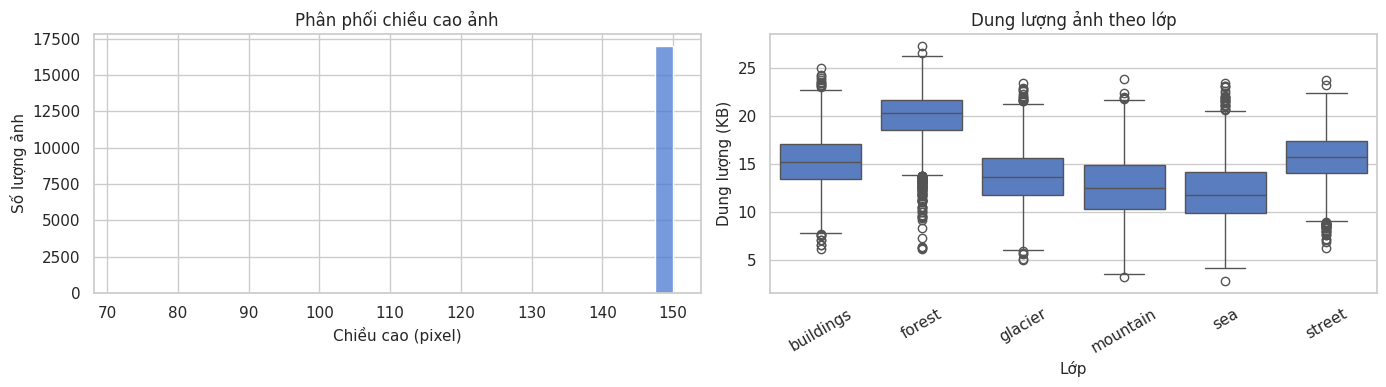

In [7]:
# Thống kê kích thước ảnh
dim_counts_train = df_train_meta.groupby(['width', 'height']).size().reset_index(name='count')
dim_counts_test = df_test_meta.groupby(['width', 'height']).size().reset_index(name='count')

print('Kích thước ảnh trong tập Train:')
display(dim_counts_train)

print('Kích thước ảnh trong tập Test:')
display(dim_counts_test)

# Kiểm tra ảnh không có kích thước 150x150
for name, df in [('Train', df_train_meta), ('Test', df_test_meta)]:
    irregular = df[(df['width'] != 150) | (df['height'] != 150)]
    ratio = len(irregular) / len(df) * 100

    print(f'{name}: {len(irregular)} ảnh khác 150x150 ({ratio:.2f}%)')

# Phân phối chiều cao và dung lượng ảnh
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=df_meta, x='height', bins=30, ax=axes[0])
axes[0].set_title('Phân phối chiều cao ảnh')
axes[0].set_xlabel('Chiều cao (pixel)')
axes[0].set_ylabel('Số lượng ảnh')

sns.boxplot(data=df_meta, x='class', y='filesize_kb', ax=axes[1])
axes[1].set_title('Dung lượng ảnh theo lớp')
axes[1].set_xlabel('Lớp')
axes[1].set_ylabel('Dung lượng (KB)')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Nhận xét:**

- **Kích thước ảnh:** Phần lớn ảnh trong cả hai tập Train và Test đều có kích thước $(150 \times 150)$. Tuy nhiên, vẫn có một số ảnh có kích thước khác với chuẩn này, gồm 48 ảnh ở tập Train (0,34%) và 7 ảnh ở tập Test (0,23%). Các ảnh này cần được kiểm tra và xử lý phù hợp trước khi đưa vào mô hình.

- **Tiền xử lý dữ liệu:** Cần đảm bảo các ảnh có cùng kích thước trước khi gom thành batch. Có thể sử dụng `Resize((150, 150))` để tránh lỗi khi ghép tensor có kích thước khác nhau.

- **Dung lượng ảnh:** Dung lượng tệp có sự khác biệt giữa các lớp. Trong đó `forest` thường có dung lượng cao hơn, còn `sea` và `mountain` có xu hướng thấp hơn. Sự khác biệt này có thể xuất phát từ mức độ chi tiết và cách nén ảnh JPEG. Tuy nhiên, cần lưu ý dung lượng tệp không phản ánh trực tiếp độ phức tạp của ảnh hay mức độ khó của bài toán phân loại.

## 3. Phân tích màu sắc và cường độ pixel

### 3.1. Thống kê các kênh màu RGB

Tính giá trị trung bình ($\mu$) và độ lệch chuẩn ($\sigma$) của ba kênh màu RGB giúp xác định đặc điểm phân phối pixel trong tập Train. Các giá trị này có thể được sử dụng để chuẩn hóa ảnh trước khi đưa vào mô hình:

$$
X_{\text{norm}} = \frac{X-\mu}{\sigma}
$$

Trong đó, $X$ là giá trị pixel đầu vào, còn $\mu$ và $\sigma$ lần lượt là giá trị trung bình và độ lệch chuẩn của từng kênh màu. Các thống kê được ước lượng từ 2.500 ảnh lấy ngẫu nhiên trong tập Train nhằm giảm thời gian tính toán.

,Channel,Mean,Std
0,Red,0.4309,0.2694
1,Green,0.4569,0.2688
2,Blue,0.4530,0.2990


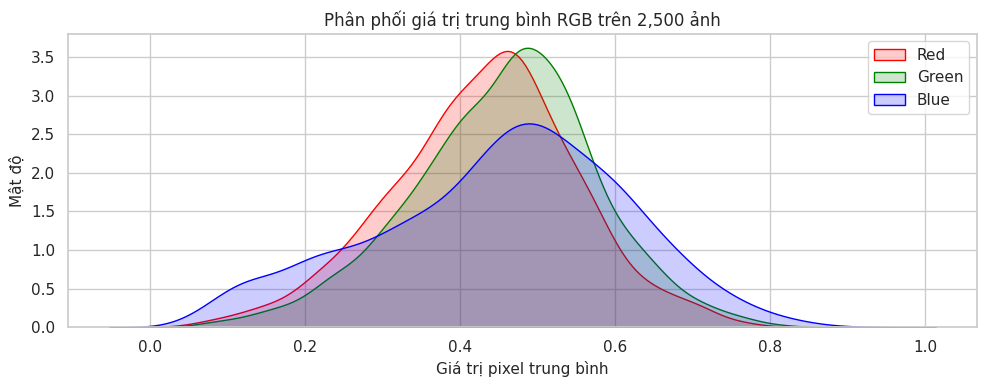

In [8]:
# Tính thống kê RGB trên 2.500 ảnh lấy ngẫu nhiên từ tập Train
SAMPLE_SIZE = 2500
sample_paths = df_train_meta.sample(
    n=SAMPLE_SIZE, random_state=RANDOM_SEED
)['filepath'].tolist()

channel_means = []
channel_stds = []

for path in sample_paths:
    with Image.open(path) as img:
        arr = np.asarray(img.convert('RGB'), dtype=np.float32) / 255.0
        channel_means.append(arr.mean(axis=(0, 1)))
        channel_stds.append(arr.std(axis=(0, 1)))

channel_means = np.array(channel_means)
channel_stds = np.array(channel_stds)

dataset_mean = channel_means.mean(axis=0)
dataset_std = np.sqrt(
    (channel_stds**2 + channel_means**2).mean(axis=0) - dataset_mean**2
)

df_color_stats = pd.DataFrame({
    'Channel': ['Red', 'Green', 'Blue'],
    'Mean': np.round(dataset_mean, 4),
    'Std': np.round(dataset_std, 4)
})

display(df_color_stats)

# Phân phối giá trị trung bình của từng kênh màu
plt.figure(figsize=(10, 4))

for i, color in enumerate(['red', 'green', 'blue']):
    sns.kdeplot(
        channel_means[:, i],
        color=color,
        label=color.capitalize(),
        fill=True,
        alpha=0.2
    )

plt.title(f'Phân phối giá trị trung bình RGB trên {SAMPLE_SIZE:,} ảnh')
plt.xlabel('Giá trị pixel trung bình')
plt.ylabel('Mật độ')
plt.legend()
plt.tight_layout()
plt.show()

**Nhận xét:**

- **Phân bố màu sắc:** Giá trị trung bình của kênh Green ($\mu_G \approx 0.457$) và Blue ($\mu_B \approx 0.453$) cao hơn Red ($\mu_R \approx 0.431$). Điều này hoàn toàn phù hợp với đặc thù của bộ dữ liệu, vốn chứa chủ yếu là ảnh phong cảnh tự nhiên ngoài trời như rừng cây xanh, mặt biển, núi non và sông băng tuyết phủ.

- **Chuẩn hóa ảnh:** Giá trị Mean và Std vừa tính toán từ tập Train sẽ được sử dụng trực tiếp để chuẩn hóa dữ liệu đầu vào khi huấn luyện mô hình. Phép chuẩn hóa này giúp các kênh màu có giá trị tập trung quanh kỳ vọng 0 và phương sai 1, từ đó hỗ trợ quá trình huấn luyện mô hình học sâu hội tụ nhanh và ổn định hơn.

Nhìn chung, việc thống kê các kênh màu cung cấp thông số thực nghiệm chuẩn xác từ chính dữ liệu bài toán để thiết lập pipeline tiền xử lý ảnh hiệu quả.

## 4. Không gian đặc trưng và khảo sát độ phân tách giữa các lớp

### 4.1. Trích xuất đặc trưng màu sắc toàn cục (RGB Color Histograms)

Để khảo sát mức độ khác biệt về màu sắc giữa các lớp, nhóm sử dụng biểu đồ histogram trên từng kênh RGB. Mỗi kênh được chia thành 8 bins, tạo thành vector gồm 24 đặc trưng cho mỗi ảnh. Thí nghiệm sử dụng 200 ảnh cho mỗi lớp, tương ứng 1.200 ảnh được lấy từ tập Train.

In [9]:

# Trích xuất histogram màu RGB cho từng ảnh
HIST_SAMPLES_PER_CLASS = 200

hist_features = []
hist_labels = []

for cls_name in classes:
    paths = df_train_meta[df_train_meta['class'] == cls_name].sample(
        n=HIST_SAMPLES_PER_CLASS, random_state=RANDOM_SEED
    )['filepath'].tolist()

    for p in paths:
        with Image.open(p) as img:
            arr = np.array(img.convert('RGB'))

            # Chia mỗi kênh RGB thành 8 bins
            r_hist, _ = np.histogram(
                arr[:, :, 0], bins=8, range=(0, 256), density=True
            )
            g_hist, _ = np.histogram(
                arr[:, :, 1], bins=8, range=(0, 256), density=True
            )
            b_hist, _ = np.histogram(
                arr[:, :, 2], bins=8, range=(0, 256), density=True
            )

            # Ghép histogram của ba kênh thành vector 24 chiều
            feat = np.concatenate([r_hist, g_hist, b_hist])
            hist_features.append(feat)
            hist_labels.append(cls_name)

X_hist = np.array(hist_features)

print(
    f"Ma trận đặc trưng màu sắc có kích thước: {X_hist.shape} "
    f"(N_samples = {len(X_hist)}, D_features = {X_hist.shape[1]})"
)


Ma trận đặc trưng màu sắc có kích thước: (1200, 24) (N_samples = 1200, D_features = 24)


### 4.2. Giảm chiều và trực quan hóa bằng t-SNE

Nhóm sử dụng t-SNE để đưa vector đặc trưng màu sắc 24 chiều về không gian 2 chiều, qua đó quan sát cách các lớp phân bố và mức độ chồng lấn khi chỉ xét thông tin màu sắc.

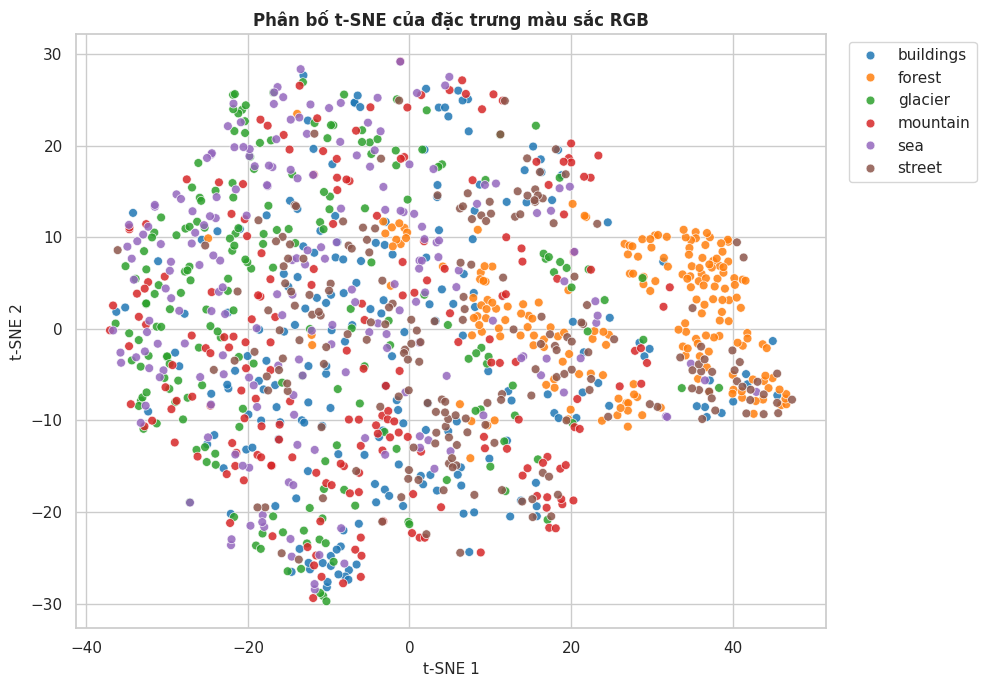

In [10]:

# Giảm chiều các đặc trưng màu sắc bằng t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=35,
    random_state=RANDOM_SEED,
    max_iter=1000
)
X_tsne = tsne.fit_transform(X_hist)

df_tsne = pd.DataFrame({
    'tSNE-1': X_tsne[:, 0],
    'tSNE-2': X_tsne[:, 1],
    'Class': hist_labels
})

# Vẽ phân bố các lớp trong không gian 2 chiều
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_tsne,
    x='tSNE-1',
    y='tSNE-2',
    hue='Class',
    palette='tab10',
    alpha=0.85,
    s=40
)

plt.title(
    'Phân bố t-SNE của đặc trưng màu sắc RGB',
    fontweight='bold'
)
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


**Nhận xét:**

- **Một số lớp có xu hướng tập trung riêng:** `forest` hình thành vùng tương đối tách biệt ở phía bên phải, có thể liên quan đến đặc trưng màu xanh của thảm thực vật. Trong khi đó, `sea` vẫn phân tán khá rộng và còn chồng lấn với `glacier`, `mountain` và `buildings` do các lớp này cùng chia sẻ tông màu xanh lam/xám của bầu trời và mặt nước.
- **Các lớp có màu sắc tương tự khó phân biệt:** `buildings` và `street` chồng lấn khá nhiều ở vùng trung tâm. Hai lớp `glacier` và `mountain` cũng khó tách biệt rõ ràng khi chỉ sử dụng histogram màu RGB.
- **Hạn chế của đặc trưng màu sắc:** Histogram ghi nhận phân bố màu nhưng không giữ lại vị trí pixel hay cấu trúc không gian của ảnh. Vì vậy, những lớp có màu sắc gần nhau nhưng khác về bố cục hoặc hình dạng có thể vẫn nằm gần nhau trong không gian đặc trưng.

Kết quả này gợi ý rằng màu sắc có thể hỗ trợ nhận diện một số lớp, nhưng chưa đủ để phân biệt tốt tất cả các lớp. Cần kết hợp thêm thông tin về kết cấu và cấu trúc không gian để đánh giá khả năng phân tách đầy đủ hơn.

### 4.3. Khảo sát các cặp lớp có khả năng nhầm lẫn cao

Dựa trên kết quả trực quan hóa ở phần trước, nhóm chọn hai cặp lớp `glacier` - `mountain` và `buildings` - `street` để xem xét sự tương đồng giữa các ảnh.

- **`glacier` và `mountain`:** Cả hai lớp đều có thể xuất hiện núi đá, tuyết, băng và bầu trời. Sự khác biệt thường nằm ở địa hình, mức độ bao phủ của băng tuyết và cách các thành phần này phân bố trong ảnh.
- **`buildings` và `street`:** Ảnh đường phố thường có các tòa nhà, phương tiện và mặt đường; ngược lại, ảnh tòa nhà cũng có thể chứa vỉa hè hoặc đường giao thông. Vì vậy, hai lớp có thể chia sẻ nhiều đặc trưng hình ảnh.

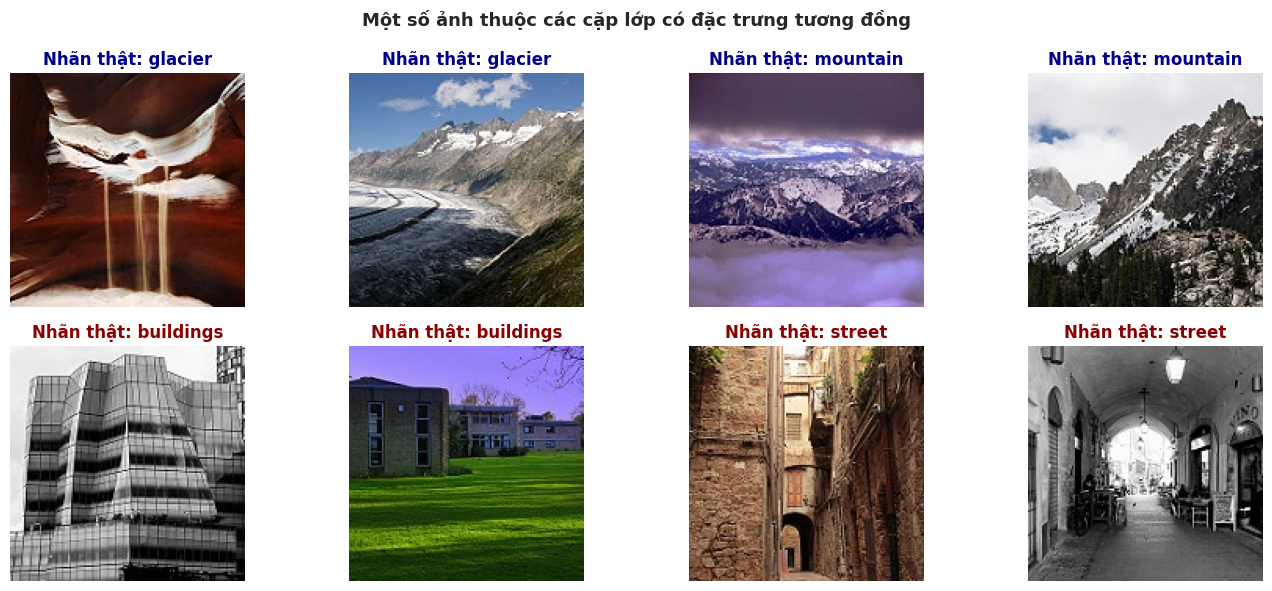

In [11]:

# Hiển thị một số ảnh thuộc hai cặp lớp dễ nhầm lẫn
fig, axes = plt.subplots(2, 4, figsize=(14, 6))

# Hai ảnh glacier và hai ảnh mountain
g_paths = df_train_meta[
    df_train_meta['class'] == 'glacier'
].sample(2, random_state=12)['filepath'].tolist()

m_paths = df_train_meta[
    df_train_meta['class'] == 'mountain'
].sample(2, random_state=12)['filepath'].tolist()

for i, p in enumerate(g_paths + m_paths):
    lbl = 'glacier' if i < 2 else 'mountain'

    with Image.open(p) as img:
        axes[0, i].imshow(img)

    axes[0, i].set_title(
        f"Nhãn thật: {lbl}",
        color='darkblue',
        fontweight='bold'
    )
    axes[0, i].axis('off')

# Hai ảnh buildings và hai ảnh street
b_paths = df_train_meta[
    df_train_meta['class'] == 'buildings'
].sample(2, random_state=99)['filepath'].tolist()

s_paths = df_train_meta[
    df_train_meta['class'] == 'street'
].sample(2, random_state=99)['filepath'].tolist()

for i, p in enumerate(b_paths + s_paths):
    lbl = 'buildings' if i < 2 else 'street'

    with Image.open(p) as img:
        axes[1, i].imshow(img)

    axes[1, i].set_title(
        f"Nhãn thật: {lbl}",
        color='darkred',
        fontweight='bold'
    )
    axes[1, i].axis('off')

axes[0, 0].set_ylabel(
    "Cặp 1: Glacier và mountain",
    fontsize=11,
    fontweight='bold'
)
axes[1, 0].set_ylabel(
    "Cặp 2: Buildings và street",
    fontsize=11,
    fontweight='bold'
)

plt.suptitle(
    "Một số ảnh thuộc các cặp lớp có đặc trưng tương đồng",
    fontsize=13,
    y=0.98,
    fontweight='bold'
)
plt.tight_layout()
plt.show()


**Nhận xét:**

- **Cặp `glacier` và `mountain`:** Hai lớp có thể có màu sắc và thành phần cảnh vật khá giống nhau. Nếu chỉ xét phân bố màu, việc phân biệt chúng sẽ gặp khó khăn; hình dạng địa hình và cách băng tuyết phân bố có thể cung cấp thêm thông tin.
- **Cặp `buildings` và `street`:** Các thành phần như tòa nhà, mặt đường và phương tiện có thể xuất hiện ở cả hai lớp. Sự khác biệt thường nằm ở đối tượng chính và bố cục tổng thể của ảnh.
- **Hàm ý đối với mô hình:** Các ví dụ này cho thấy chỉ sử dụng màu sắc hoặc một số đặc trưng cục bộ có thể chưa đủ để phân biệt các lớp. Mô hình cần học thêm đặc trưng hình dạng, bố cục và ngữ cảnh của cảnh vật. CNN có thể học những đặc trưng này qua nhiều tầng; các mô hình pretrained như ResNet hoặc EfficientNet cũng là những lựa chọn đáng thử nghiệm.

Tuy nhiên, một số ảnh minh họa chưa đủ để kết luận mô hình nào sẽ phân loại sai hoặc kiến trúc nào tốt hơn. Cần đánh giá bằng kết quả thực nghiệm, chẳng hạn confusion matrix và precision, recall theo từng lớp.

## 5. Tổng hợp kết quả EDA

Dựa trên các kết quả phân tích và trực quan hóa ở những phần trước, nhóm tổng hợp các phát hiện chính cùng hướng xử lý dự kiến cho giai đoạn xây dựng mô hình.

**Bảng đối chiếu kết quả EDA và kế hoạch thực hiện**

| Khía cạnh | Kết quả EDA | Định hướng xử lý |
|---|---|---|
| **1. Tính toàn vẹn của ảnh** | Các tệp ảnh đã kiểm tra đều hợp lệ, có 3 kênh màu RGB. | Không cần lọc ảnh lỗi trong phạm vi đã kiểm tra. Tiếp tục đọc ảnh từ đường dẫn trong bộ dữ liệu. |
| **2. Kích thước ảnh** | Có 48 ảnh Train và 7 ảnh Test không có kích thước 150 × 150. | Resize ảnh về cùng kích thước trước khi đưa vào mini-batch, chẳng hạn dùng `transforms.Resize((150, 150))`. |
| **3. Phân bố nhãn** | Sáu lớp có số lượng mẫu tương đối đồng đều, tỷ lệ số mẫu giữa lớp nhiều nhất và ít nhất là 1,15. | Có thể bắt đầu với `CrossEntropyLoss` tiêu chuẩn, theo dõi Accuracy và Macro F1. Chỉ cân nhắc xử lý mất cân bằng nếu kết quả theo từng lớp cho thấy cần thiết. |
| **4. Phân bố màu RGB** | Kênh Green và Blue có giá trị trung bình cao hơn Red trong tập ảnh được khảo sát. | Tính mean và std trên tập Train để chuẩn hóa dữ liệu. Nếu dùng backbone pretrained, áp dụng cách chuẩn hóa phù hợp với trọng số pretrained, chẳng hạn ImageNet. |
| **5. Bố cục ảnh** | Nhiều ảnh phong cảnh có đường chân trời nằm ngang và bầu trời ở phía trên. | Có thể dùng `RandomHorizontalFlip` với xác suất phù hợp. Không ưu tiên `RandomVerticalFlip` vì dễ tạo ra các cảnh không tự nhiên. |
| **6. Dung lượng ảnh và mức độ chi tiết** | `forest` có dung lượng tệp JPEG cao hơn với nhiều chi tiết tán lá, còn `sea` và `mountain` có xu hướng dung lượng thấp hơn và nhiều vùng bề mặt đồng nhất hơn trong các ảnh được khảo sát. | Thử nghiệm mô hình có khả năng học cả đặc trưng cục bộ lẫn bố cục tổng thể; đối chiếu kết quả giữa các cấu hình thay vì xác định độ sâu mạng chỉ từ EDA. |
| **7. Khả năng phân biệt giữa các lớp** | Các lớp `glacier` - `mountain` và `buildings` - `street` có những đặc trưng hình ảnh tương đồng. | Thử nghiệm các backbone như ResNet-18, ResNet-34 hoặc EfficientNet-B0. Dùng confusion matrix và các chỉ số theo lớp để xác định những cặp dễ nhầm lẫn. |

**Kết luận**

EDA giúp nhóm hiểu rõ hơn về chất lượng dữ liệu, phân bố màu sắc, kết cấu và những điểm tương đồng giữa các lớp của bộ dữ liệu Intel Image Classification. Từ đó, nhóm xác định được các bước tiền xử lý cần thiết và một số hướng lựa chọn mô hình để thử nghiệm.

Các đề xuất trên là cơ sở ban đầu cho quá trình huấn luyện, không phải kết luận về hiệu quả của từng kỹ thuật. Nhóm sẽ tiếp tục đánh giá trên tập validation để lựa chọn cấu hình phù hợp, đồng thời sử dụng kết quả trên tập Test cho đánh giá cuối cùng sau khi hoàn tất việc lựa chọn mô hình.

# PHẦN II: CHUẨN BỊ DỮ LIỆU, PHÂN CHIA PHÂN VÙNG & DATA AUGMENTATION PIPELINE
Dựa trên các đúc kết từ Phần I (EDA), chúng ta thiết lập cơ chế phân chia dữ liệu Stratified Split và xây dựng pipeline tăng cường dữ liệu nhằm mở rộng không gian mẫu.

## 2. Chuẩn bị Dữ liệu và Phân chia Phân vùng (Dataset Preparation & Stratified Split)

Trong bài toán học máy chuẩn mực:
- **Tập Train (Huấn luyện)**: Dùng để cập nhật gradient của trọng số mô hình.
- **Tập Validation (Kiểm định)**: Dùng để theo dõi mức độ tổng quát hóa, tinh chỉnh siêu tham số (*Hyperparameter Tuning*) và kích hoạt dừng sớm (*Early Stopping*).
- **Tập Test (Kiểm thử)**: Hoàn toàn độc lập, chỉ được đánh giá duy nhất một lần ở cuối quá trình sau khi đã chốt mô hình tốt nhất.

Do bộ dữ liệu gốc chỉ phân sẵn thành `seg_train` (14.034 ảnh) và `seg_test` (3.000 ảnh), chúng ta sẽ tiến hành tách tập `seg_train` thành:
- **Tập Train**: 85% (~11.928 ảnh).
- **Tập Validation**: 15% (~2.106 ảnh).
Việc phân chia sử dụng phương pháp **Stratified Split** dựa trên nhãn lớp nhằm bảo đảm tỷ lệ giữa các lớp trong cả hai tập Train và Val là hoàn toàn tương đồng.

In [12]:
def collect_image_metadata(directory, split_name):
    supported_extensions = {".jpg", ".jpeg", ".png"}
    records = []

    class_folders = sorted([d for d in directory.iterdir() if d.is_dir()])
    for cls_dir in class_folders:
        class_name = cls_dir.name
        img_paths = sorted([
            p for p in cls_dir.iterdir()
            if p.is_file() and p.suffix.lower() in supported_extensions
        ])
        for p in img_paths:
            records.append({
                "filepath": str(p),
                "filename": p.name,
                "class": class_name,
                "split": split_name
            })
    return pd.DataFrame(records)

# Thu thập metadata của tập train và test
df_train_full = collect_image_metadata(TRAIN_DIR, "train_full")
df_test = collect_image_metadata(TEST_DIR, "test")

# Danh sách lớp và ánh xạ từ nhãn chuỗi sang chỉ số số nguyên (0..5)
classes = sorted(df_train_full['class'].unique())
NUM_CLASSES = len(classes)
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
idx_to_class = {i: cls_name for i, cls_name in enumerate(classes)}

# Phân chia Stratified Train/Val từ df_train_full (85% Train, 15% Val)
df_train, df_val = train_test_split(
    df_train_full,
    test_size=0.15,
    random_state=RANDOM_SEED,
    stratify=df_train_full['class']
)

# Cập nhật nhãn split
df_train = df_train.copy()
df_val = df_val.copy()
df_train['split'] = 'train'
df_val['split'] = 'val'

print(f"Tổng số lớp nhận diện ({len(classes)}): {classes}")
print("-" * 60)
print(f"Số lượng mẫu tập Train      : {len(df_train):,} ảnh (85.0%)")
print(f"Số lượng mẫu tập Validation : {len(df_val):,} ảnh (15.0%)")
print(f"Số lượng mẫu tập Test       : {len(df_test):,} ảnh (100% độc lập)")
print("-" * 60)

# Hiển thị số lượng mẫu theo từng lớp trên các tập
split_summary = pd.DataFrame({
    'Train (85%)': df_train['class'].value_counts(),
    'Val (15%)': df_val['class'].value_counts(),
    'Test': df_test['class'].value_counts()
}).loc[classes]
display(split_summary)

Tổng số lớp nhận diện (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
------------------------------------------------------------
Số lượng mẫu tập Train      : 11,928 ảnh (85.0%)
Số lượng mẫu tập Validation : 2,106 ảnh (15.0%)
Số lượng mẫu tập Test       : 3,000 ảnh (100% độc lập)
------------------------------------------------------------


,Train (85%),Val (15%),Test
class,,,
buildings,1862,329,437
forest,1930,341,474
glacier,2043,361,553
mountain,2135,377,525
sea,1933,341,510
street,2025,357,501


## 3. Xây dựng Data Pipeline & Data Augmentation

Để đánh giá công bằng giữa mô hình tự train từ đầu và mô hình pretrained, ta tách rõ 2 bộ chuẩn hóa đầu vào:
- **Pipeline `150x150` (Dataset Mean/Std):** Dùng cho `SimpleBaselineCNN` và `ResNet-18 (From Scratch)` theo đúng kích thước gốc và phân bố màu đo được từ EDA.
- **Pipeline `224x224` (ImageNet Mean/Std):** Dùng cho `ResNet-18` và `ViT-B/16` pretrained trên ImageNet để khớp phân bố trọng số ban đầu.

Các phép augmentation trên tập Train (`RandomHorizontalFlip`, `RandomResizedCrop`, `ColorJitter`, `RandomRotation`) giúp tăng đa dạng góc nhìn và ánh sáng; tập Val/Test chỉ Resize và Normalize. Ngoài ra, `train_loader` được gắn `worker_init_fn` và `generator` cố định seed để giữ thứ tự xáo trộn và augmentation ổn định hơn giữa các lần chạy.

In [13]:
# Chuẩn hóa cho tập dữ liệu Intel Image (150x150) và chuẩn ImageNet (224x224)
DATASET_MEAN  = [0.430, 0.457, 0.453]
DATASET_STD   = [0.269, 0.264, 0.280]
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def make_transforms(img_size, mean, std):
    train_tf = T.Compose([
        T.Resize((img_size, img_size)),
        T.RandomHorizontalFlip(p=0.5),
        T.RandomResizedCrop(size=(img_size, img_size), scale=(0.85, 1.0), ratio=(0.9, 1.1)),
        T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
        T.RandomRotation(degrees=10),
        T.ToTensor(),
        T.Normalize(mean=mean, std=std)
    ])
    eval_tf = T.Compose([
        T.Resize((img_size, img_size)),
        T.ToTensor(),
        T.Normalize(mean=mean, std=std)
    ])
    return train_tf, eval_tf

class IntelImageDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['filepath']).convert('RGB')
        label = class_to_idx[row['class']]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def build_dataloaders(img_size, mean, std, batch_size=64):
    train_tf, eval_tf = make_transforms(img_size, mean, std)
    train_ds = IntelImageDataset(df_train, transform=train_tf)
    val_ds   = IntelImageDataset(df_val, transform=eval_tf)
    test_ds  = IntelImageDataset(df_test, transform=eval_tf)

    num_workers = 2 if os.name != 'nt' else 0
    g = torch.Generator()
    g.manual_seed(RANDOM_SEED)

    train_ld = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True,
        num_workers=num_workers, pin_memory=torch.cuda.is_available(),
        worker_init_fn=seed_worker, generator=g
    )
    val_ld = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=torch.cuda.is_available()
    )
    test_ld = DataLoader(
        test_ds, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=torch.cuda.is_available()
    )
    return train_ld, val_ld, test_ld, eval_tf

BATCH_SIZE = 64
train_loader, val_loader, test_loader, val_test_transforms = build_dataloaders(
    150, DATASET_MEAN, DATASET_STD, batch_size=BATCH_SIZE
)
train_loader_224, val_loader_224, test_loader_224, val_test_transforms_224 = build_dataloaders(
    224, IMAGENET_MEAN, IMAGENET_STD, batch_size=BATCH_SIZE
)

print(f"Batches (batch_size={BATCH_SIZE}) - Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

Batches (batch_size=64) - Train: 187 | Val: 33 | Test: 47


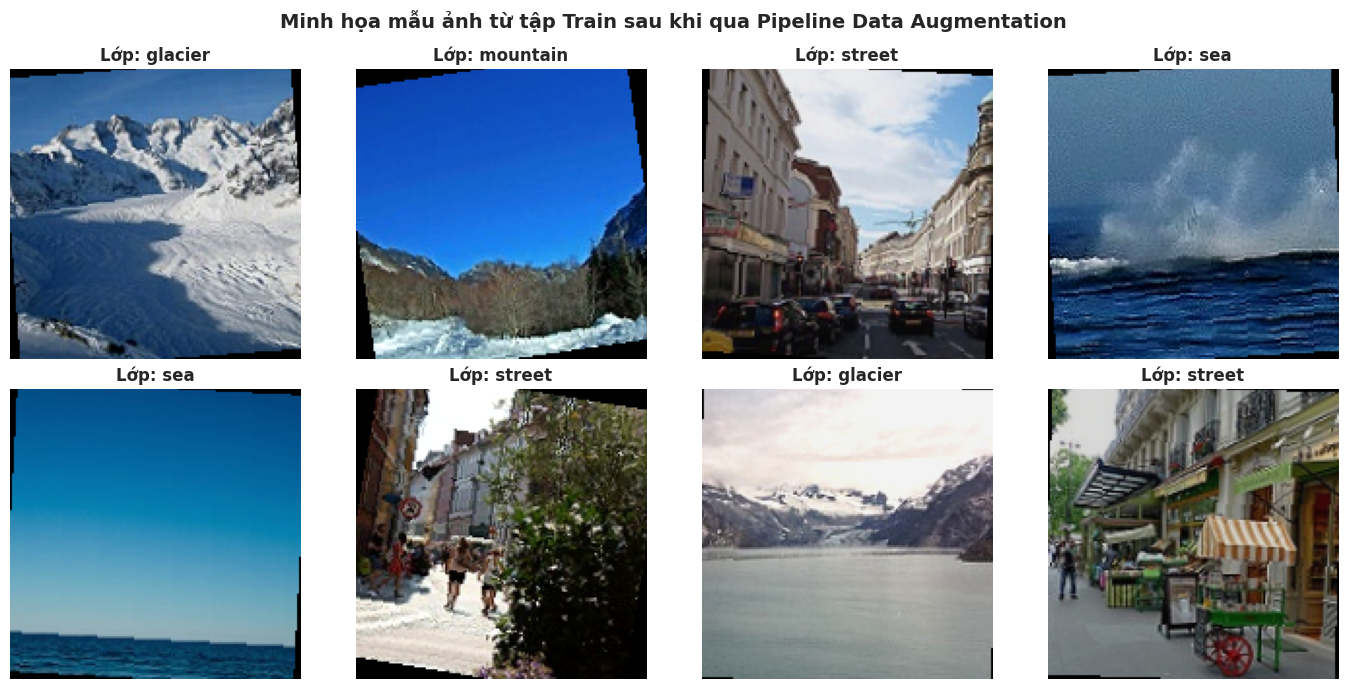

In [14]:
# Trực quan hóa một batch ảnh sau khi áp dụng Data Augmentation
def unnormalize_image(tensor, mean=DATASET_MEAN, std=DATASET_STD):
    img = tensor.clone().detach().cpu().numpy().transpose(1, 2, 0)
    img = img * np.array(std) + np.array(mean)
    img = np.clip(img, 0, 1)
    return img

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for idx, ax in enumerate(axes.flat):
    img_display = unnormalize_image(images[idx])
    cls_name = idx_to_class[labels[idx].item()]
    ax.imshow(img_display)
    ax.set_title(f"Lớp: {cls_name}", fontweight='bold')
    ax.axis('off')

plt.suptitle("Minh họa mẫu ảnh từ tập Train sau khi qua Pipeline Data Augmentation", fontsize=14, y=0.98, fontweight='bold')
plt.tight_layout()
plt.show()

# PHẦN III: THIẾT KẾ CÁC KIẾN TRÚC VÀ CHIẾN LƯỢC HUẤN LUYỆN

Thay vì chỉ so 2 mô hình, phần này tổ chức thực nghiệm theo 4 trục rõ ràng:
1. **SimpleBaselineCNN vs ResNet-18 (From Scratch):** Mạng CNN 4 tầng nhẹ (0.42M) so với ResNet-18 (11.18M) khi cùng tự học từ đầu trên ~12K ảnh.
2. **Linear Probe vs Fine-tuning (trên cùng ResNet-18 Pretrained):** So sánh giữa đóng băng toàn bộ backbone (chỉ train head ~3K tham số) và mở khóa tầng sâu `layer4` với tốc độ học phân tầng (Differential LR).
3. **CNN (`ResNet-18`) vs Vision Transformer (`ViT-B/16`):** Đối chiếu cách trích xuất đặc trưng cục bộ của tích chập với cơ chế Self-Attention toàn cục.
4. **Supervised vs Zero-shot (`CLIP ViT-B/32`):** Kiểm tra mô hình ngôn ngữ–thị giác phân loại trực tiếp 6 lớp qua text prompt mà không cần huấn luyện lại.

## 4. Xây dựng Mạng Đối chứng Thực nghiệm (Baseline Simple CNN)

Để đánh giá khách quan năng lực của mô hình học sâu hiện đại, chúng ta xây dựng một mạng tích chập đơn giản (Plain CNN 4 khối không có Skip Connection) với ~0.42M tham số làm mốc tham chiếu cơ sở.

In [15]:
class SimpleBaselineCNN(nn.Module):
    def __init__(self, num_classes=6, dropout_rate=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

num_cls = len(classes) if "classes" in globals() else 6
_tmp_base = SimpleBaselineCNN(num_classes=num_cls)
print(f"SimpleBaselineCNN: {sum(p.numel() for p in _tmp_base.parameters()):,} tham số (~0.42M)")
del _tmp_base

SimpleBaselineCNN: 423,046 tham số (~0.42M)


## 5. Hàm Khởi tạo ResNet-18 (3 chế độ) và ViT-B/16

- **`ResNet-18`** hỗ trợ 3 chế độ qua tham số `mode`:
  - `scratch`: trọng số ngẫu nhiên, học toàn bộ mạng trên ảnh `150x150`.
  - `linear_probe`: tải trọng số ImageNet, đóng băng toàn bộ backbone, chỉ học tầng `fc`.
  - `finetune`: tải trọng số ImageNet, mở khóa khối tích chập cuối `layer4` cùng `fc` để tinh chỉnh đặc trưng cho ảnh phong cảnh.
- **`ViT-B/16`** chia ảnh `224x224` thành lưới các patch `16x16` và xử lý bằng Self-Attention. Với ~12K ảnh train, ta dùng trọng số pretrained ImageNet và mở khóa 2 block Encoder cuối cùng với `heads` (không train ViT từ đầu vì thiếu inductive bias của CNN nên dễ overfit khi dữ liệu nhỏ).

In [16]:
def build_resnet18(num_classes=6, mode="linear_probe"):
    """mode: 'scratch' | 'linear_probe' | 'finetune'"""
    weights = None if mode == "scratch" else models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)

    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, num_classes)
    )

    if mode == "linear_probe":
        for name, param in model.named_parameters():
            if not name.startswith("fc."):
                param.requires_grad = False
    elif mode == "finetune":
        for name, param in model.named_parameters():
            if not (name.startswith("layer4.") or name.startswith("fc.")):
                param.requires_grad = False

    return model

def build_vit_b16(num_classes=6, unfreeze_last_blocks=2):
    """Khởi tạo ViT-B/16 pretrained, mở khóa `unfreeze_last_blocks` encoder cuối + heads."""
    model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
    in_features = model.heads.head.in_features
    model.heads.head = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(in_features, num_classes)
    )

    for param in model.parameters():
        param.requires_grad = False

    total_blocks = len(model.encoder.layers)
    for idx in range(total_blocks - unfreeze_last_blocks, total_blocks):
        for param in model.encoder.layers[idx].parameters():
            param.requires_grad = True
    for param in model.encoder.ln.parameters():
        param.requires_grad = True
    for param in model.heads.parameters():
        param.requires_grad = True

    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

for label, m in [
    ("ResNet-18 (Scratch)", build_resnet18(num_cls, "scratch")),
    ("ResNet-18 (Linear Probe)", build_resnet18(num_cls, "linear_probe")),
    ("ResNet-18 (Fine-tune layer4+fc)", build_resnet18(num_cls, "finetune")),
    ("ViT-B/16 (Fine-tune 2 blocks+head)", build_vit_b16(num_cls, 2)),
]:
    tot, trn = count_params(m)
    print(f"{label:36s} | Total: {tot:10,d} | Trainable: {trn:10,d} ({trn/tot*100:5.1f}%)")
    del m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:04<00:00, 75.3MB/s]


ResNet-18 (Scratch)                  | Total: 11,179,590 | Trainable: 11,179,590 (100.0%)
ResNet-18 (Linear Probe)             | Total: 11,179,590 | Trainable:      3,078 (  0.0%)
ResNet-18 (Fine-tune layer4+fc)      | Total: 11,179,590 | Trainable:  8,396,806 ( 75.1%)
ViT-B/16 (Fine-tune 2 blocks+head)   | Total: 85,803,270 | Trainable: 14,181,894 ( 16.5%)


# PHẦN IV: HUẤN LUYỆN VÀ ĐỐI CHIẾU THỰC NGHIỆM

## 6. Thiết lập Training Engine & Chỉ số Engineering

Tất cả các mô hình supervised dùng chung một pipeline huấn luyện gọn nhẹ để loại bỏ code lặp và đảm bảo công bằng:
- **Loss:** `CrossEntropyLoss(label_smoothing=0.05)` giảm dự đoán quá tự tin ở các cặp lớp dễ nhầm (`glacier` vs `mountain`).
- **Optimizer & Differential LR:** `AdamW` + `CosineAnnealingLR`. Khi fine-tune, phần backbone pretrained học với tốc độ nhỏ (`1e-4` cho ResNet, `5e-5` cho ViT) để không phá vỡ đặc trưng đã có, còn tầng phân loại mới học nhanh hơn (`1e-3`).
- **Chi phí hệ thống:** Ngoài Accuracy và Macro-F1, mỗi mô hình được đo thêm thời gian train, Peak GPU VRAM và **Inference Latency (ms/ảnh)** trên tập Test.

In [17]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4, checkpoint_path="best_model.pth"):
        self.patience = patience
        self.min_delta = min_delta
        self.checkpoint_path = checkpoint_path
        self.counter = 0
        self.best_loss = np.inf
        self.early_stop = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            torch.save(model.state_dict(), self.checkpoint_path)
            return True
        self.counter += 1
        if self.counter >= self.patience:
            self.early_stop = True
        return False

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += outputs.argmax(1).eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate_epoch(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        running_loss += loss.item() * images.size(0)
        correct += outputs.argmax(1).eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def get_predictions_and_ground_truth(model, dataloader, device):
    model.eval()
    all_preds, all_targets, all_probs = [], [], []
    for images, labels in dataloader:
        images = images.to(device)
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_targets.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_targets), np.array(all_probs)

@torch.no_grad()
def benchmark_inference(model, dataloader, device, max_batches=20):
    """Đo tốc độ suy luận trung bình (ms/ảnh) trên GPU/CPU."""
    model.eval()
    sample_batch, _ = next(iter(dataloader))
    sample_batch = sample_batch.to(device)
    _ = model(sample_batch[:1])  # warmup
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    n_images = 0
    t0 = time.perf_counter()
    for b_idx, (images, _) in enumerate(dataloader):
        if b_idx >= max_batches:
            break
        images = images.to(device)
        _ = model(images)
        n_images += images.size(0)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    return (elapsed / n_images) * 1000.0  # ms / ảnh

def fit_model(model, train_loader, val_loader, criterion, optimizer, scheduler,
              epochs=10, patience=5, checkpoint_path="best_model.pth", model_name="Model"):
    print(f"\n=== HUẤN LUYỆN: {model_name} ({epochs} epochs) ===")
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'lr': []}
    early_stopping = EarlyStopping(patience=patience, checkpoint_path=checkpoint_path)

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        ep_t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc = evaluate_epoch(model, val_loader, criterion, device)
        cur_lr = optimizer.param_groups[-1]['lr']
        if scheduler is not None:
            scheduler.step()

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)
        history['lr'].append(cur_lr)

        saved_tag = "[best]" if early_stopping(va_loss, model) else ""
        print(
            f"Epoch {epoch:02d}/{epochs:02d} [{time.time()-ep_t0:.1f}s] | "
            f"Train: {tr_loss:.4f} ({tr_acc*100:.2f}%) | "
            f"Val: {va_loss:.4f} ({va_acc*100:.2f}%) {saved_tag}"
        )
        if early_stopping.early_stop:
            print(f"--> Early stopping tại epoch {epoch}.")
            break

    history['total_time_sec'] = time.time() - start_time
    history['peak_vram_mb'] = (torch.cuda.max_memory_allocated() / 1e6) if torch.cuda.is_available() else 0.0
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    return history

def plot_learning_curves(history, model_title="Mô hình"):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(epochs, history['train_loss'], 'o-', label='Train Loss')
    ax1.plot(epochs, history['val_loss'], 's-', label='Val Loss')
    ax1.set_title(f"Loss - {model_title}", fontweight='bold')
    ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.5)

    ax2.plot(epochs, [a * 100 for a in history['train_acc']], 'o-', label='Train Acc')
    ax2.plot(epochs, [a * 100 for a in history['val_acc']], 's-', label='Val Acc')
    ax2.set_title(f"Accuracy (%) - {model_title}", fontweight='bold')
    ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Kho lưu kết quả chung cho toàn bộ thực nghiệm
EXPERIMENT_RESULTS = []
PREDICTIONS_STORE = {}

def run_supervised_experiment(name, paradigm, model, train_ld, val_ld, test_ld,
                              epochs, head_lr=1e-3, backbone_lr=None, weight_decay=1e-3,
                              patience=4, checkpoint_path="best.pth"):
    seed_everything(RANDOM_SEED)
    model = model.to(device)
    total_params, trainable_params = count_params(model)

    if backbone_lr is not None:
        head_params, bb_params = [], []
        for pname, p in model.named_parameters():
            if not p.requires_grad:
                continue
            if pname.startswith(("fc.", "heads.", "classifier.")):
                head_params.append(p)
            else:
                bb_params.append(p)
        param_groups = [
            {"params": bb_params, "lr": backbone_lr},
            {"params": head_params, "lr": head_lr},
        ]
    else:
        param_groups = [{"params": [p for p in model.parameters() if p.requires_grad], "lr": head_lr}]

    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    optimizer = torch.optim.AdamW(param_groups, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    history = fit_model(
        model, train_ld, val_ld, criterion, optimizer, scheduler,
        epochs=epochs, patience=patience, checkpoint_path=checkpoint_path, model_name=name
    )
    plot_learning_curves(history, model_title=name)

    y_p, y_t, y_pr = get_predictions_and_ground_truth(model, test_ld, device)
    latency_ms = benchmark_inference(model, test_ld, device)

    acc = accuracy_score(y_t, y_p)
    f1_m = f1_score(y_t, y_p, average='macro')
    EXPERIMENT_RESULTS.append({
        "Model": name,
        "Paradigm": paradigm,
        "Total Params": total_params,
        "Trainable Params": trainable_params,
        "Epochs Run": len(history['train_loss']),
        "Train Time (s)": round(history['total_time_sec'], 1),
        "Peak VRAM (MB)": round(history['peak_vram_mb'], 1),
        "Latency (ms/img)": round(latency_ms, 2),
        "Test Accuracy (%)": round(acc * 100, 2),
        "Macro F1 (%)": round(f1_m * 100, 2),
    })
    PREDICTIONS_STORE[name] = {"y_pred": y_p, "y_true": y_t, "y_probs": y_pr}
    print(f"--> [{name}] Test Acc: {acc*100:.2f}% | Macro F1: {f1_m*100:.2f}% | Latency: {latency_ms:.2f} ms/img")
    return model, history

### 7.1 Nhóm Train From Scratch (`SimpleBaselineCNN` vs `ResNet-18 Scratch`)
Cùng dùng ảnh `150x150` (chuẩn hóa theo mean/std của dataset) để xem một mạng sâu 11.18M tham số tự học từ đầu có vượt được mạng nhỏ 0.42M hay không khi chỉ có ~12K ảnh train.


=== HUẤN LUYỆN: SimpleBaselineCNN (Scratch) (10 epochs) ===
Epoch 01/10 [48.1s] | Train: 1.1116 (59.02%) | Val: 0.8738 (73.55%) [best]
Epoch 02/10 [44.9s] | Train: 0.8895 (71.76%) | Val: 0.7584 (78.63%) [best]
Epoch 03/10 [45.1s] | Train: 0.8272 (74.83%) | Val: 0.7735 (78.11%) 
Epoch 04/10 [44.6s] | Train: 0.7673 (77.89%) | Val: 0.7071 (80.77%) [best]
Epoch 05/10 [46.5s] | Train: 0.7361 (79.28%) | Val: 0.6775 (82.34%) [best]
Epoch 06/10 [46.5s] | Train: 0.6944 (80.91%) | Val: 0.6626 (81.43%) [best]
Epoch 07/10 [47.1s] | Train: 0.6728 (81.87%) | Val: 0.5956 (85.38%) [best]
Epoch 08/10 [45.2s] | Train: 0.6483 (83.58%) | Val: 0.6316 (84.76%) 
Epoch 09/10 [45.4s] | Train: 0.6327 (84.31%) | Val: 0.5916 (85.75%) [best]
Epoch 10/10 [44.8s] | Train: 0.6233 (84.61%) | Val: 0.5835 (86.18%) [best]


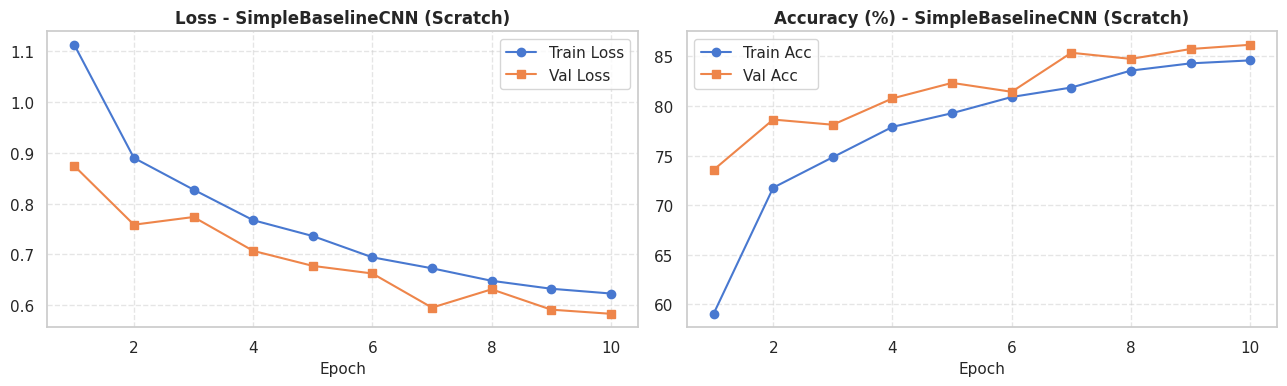

--> [SimpleBaselineCNN (Scratch)] Test Acc: 85.80% | Macro F1: 85.87% | Latency: 1.76 ms/img

=== HUẤN LUYỆN: ResNet-18 (From Scratch) (12 epochs) ===
Epoch 01/12 [50.0s] | Train: 1.0941 (62.21%) | Val: 1.0775 (66.19%) [best]
Epoch 02/12 [48.7s] | Train: 0.8420 (74.38%) | Val: 0.8865 (73.84%) [best]
Epoch 03/12 [47.5s] | Train: 0.7495 (78.57%) | Val: 0.7719 (77.54%) [best]
Epoch 04/12 [48.3s] | Train: 0.7053 (80.73%) | Val: 0.6494 (83.19%) [best]
Epoch 05/12 [47.4s] | Train: 0.6565 (82.86%) | Val: 0.6867 (82.15%) 
Epoch 06/12 [47.6s] | Train: 0.6167 (84.74%) | Val: 0.6591 (83.33%) 
Epoch 07/12 [48.2s] | Train: 0.5862 (85.86%) | Val: 0.6201 (84.66%) [best]
Epoch 08/12 [47.4s] | Train: 0.5527 (87.27%) | Val: 0.5376 (88.56%) [best]
Epoch 09/12 [48.2s] | Train: 0.5268 (88.53%) | Val: 0.5496 (87.32%) 
Epoch 10/12 [48.3s] | Train: 0.4984 (89.40%) | Val: 0.5159 (89.17%) [best]
Epoch 11/12 [47.5s] | Train: 0.4729 (90.93%) | Val: 0.5019 (89.89%) [best]
Epoch 12/12 [48.7s] | Train: 0.4583 (91.40

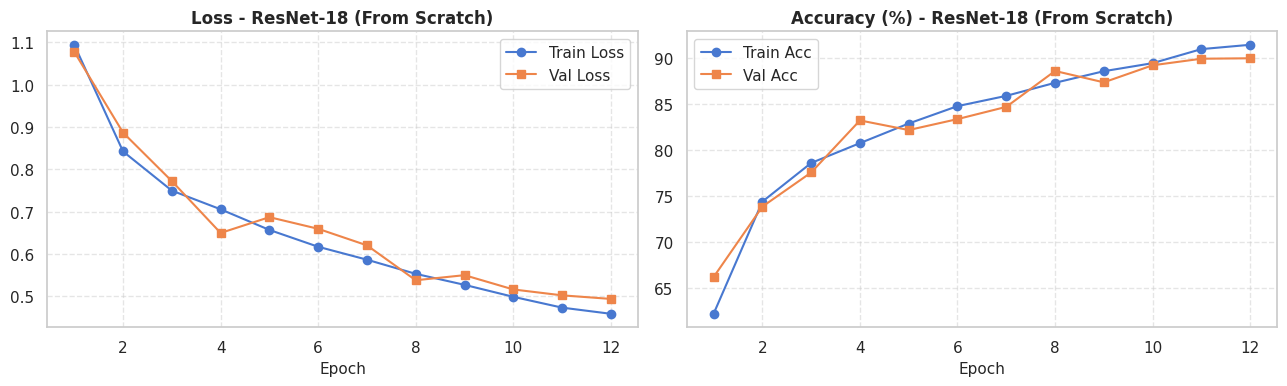

--> [ResNet-18 (From Scratch)] Test Acc: 89.40% | Macro F1: 89.50% | Latency: 2.02 ms/img


In [18]:
model_baseline, history_baseline = run_supervised_experiment(
    name="SimpleBaselineCNN (Scratch)",
    paradigm="From Scratch (150x150)",
    model=SimpleBaselineCNN(num_classes=len(classes)),
    train_ld=train_loader, val_ld=val_loader, test_ld=test_loader,
    epochs=10, head_lr=1e-3, weight_decay=1e-2, patience=5,
    checkpoint_path="best_baseline_cnn.pth"
)

model_resnet_scratch, history_resnet_scratch = run_supervised_experiment(
    name="ResNet-18 (From Scratch)",
    paradigm="From Scratch (150x150)",
    model=build_resnet18(num_classes=len(classes), mode="scratch"),
    train_ld=train_loader, val_ld=val_loader, test_ld=test_loader,
    epochs=12, head_lr=1e-3, weight_decay=1e-2, patience=5,
    checkpoint_path="best_resnet18_scratch.pth"
)

### 7.2 Nhóm Pretrained & Kiến trúc hiện đại (`ResNet-18` vs `ViT-B/16`)
Tất cả dùng pipeline `224x224` chuẩn ImageNet:
- `ResNet-18 (Linear Probe)`: đóng băng backbone, chỉ train `fc`.
- `ResNet-18 (Fine-tune)`: mở khóa `layer4` (`lr=1e-4`) và `fc` (`lr=1e-3`).
- `ViT-B/16 (Fine-tune)`: mở khóa 2 block Transformer cuối (`lr=5e-5`) và `heads` (`lr=1e-3`).


=== HUẤN LUYỆN: ResNet-18 (Linear Probe) (5 epochs) ===
Epoch 01/05 [78.3s] | Train: 0.8862 (73.11%) | Val: 0.5684 (87.70%) [best]
Epoch 02/05 [79.7s] | Train: 0.6557 (83.49%) | Val: 0.5469 (88.41%) [best]
Epoch 03/05 [79.3s] | Train: 0.6350 (83.95%) | Val: 0.5286 (90.03%) [best]
Epoch 04/05 [78.6s] | Train: 0.6174 (84.98%) | Val: 0.5272 (89.65%) [best]
Epoch 05/05 [75.8s] | Train: 0.6111 (85.29%) | Val: 0.5197 (90.36%) [best]


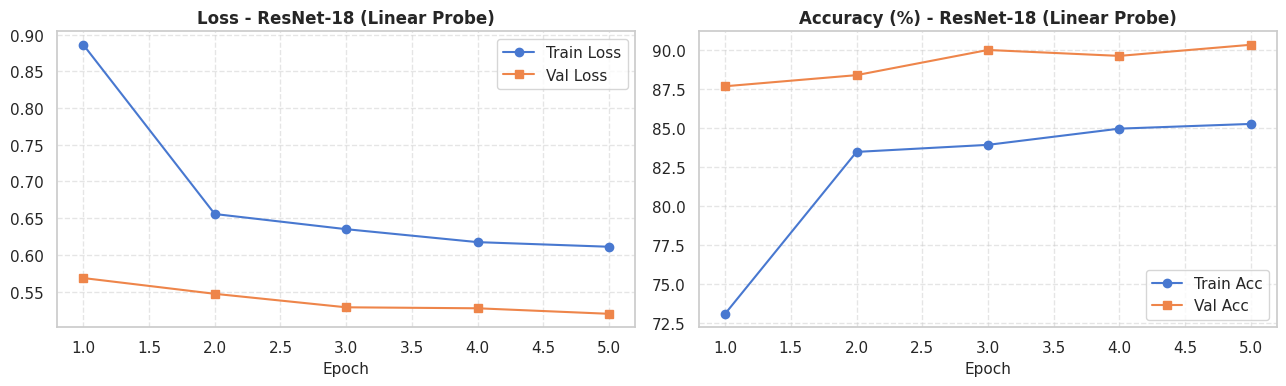

--> [ResNet-18 (Linear Probe)] Test Acc: 89.87% | Macro F1: 90.02% | Latency: 3.00 ms/img

=== HUẤN LUYỆN: ResNet-18 (Fine-tune) (6 epochs) ===
Epoch 01/06 [73.0s] | Train: 0.5722 (87.34%) | Val: 0.4649 (91.26%) [best]
Epoch 02/06 [72.6s] | Train: 0.4460 (92.52%) | Val: 0.4313 (92.88%) [best]
Epoch 03/06 [74.0s] | Train: 0.4089 (94.01%) | Val: 0.4282 (93.45%) [best]
Epoch 04/06 [73.2s] | Train: 0.3792 (95.31%) | Val: 0.4194 (93.49%) [best]
Epoch 05/06 [71.9s] | Train: 0.3591 (96.33%) | Val: 0.4253 (93.68%) 
Epoch 06/06 [74.4s] | Train: 0.3467 (96.78%) | Val: 0.4185 (94.06%) [best]


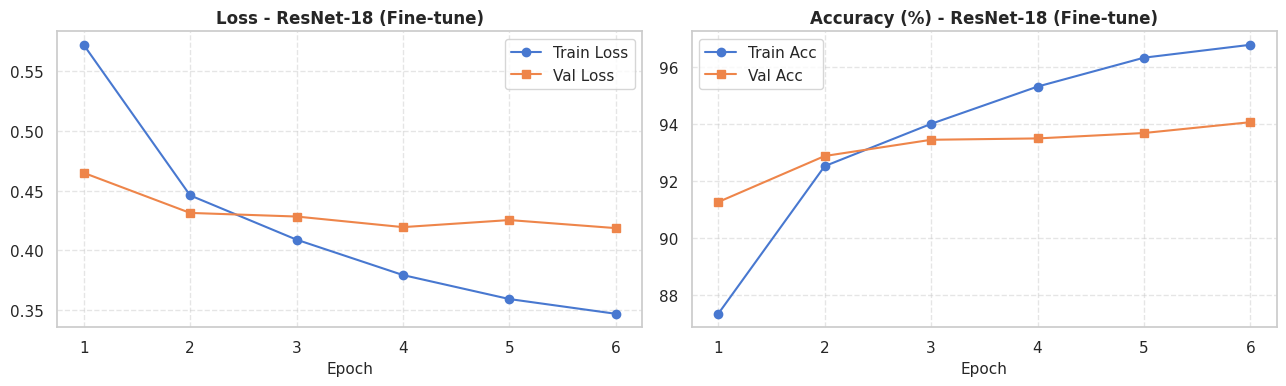

--> [ResNet-18 (Fine-tune)] Test Acc: 93.90% | Macro F1: 93.99% | Latency: 3.42 ms/img

=== HUẤN LUYỆN: ViT-B/16 (Fine-tune) (6 epochs) ===
Epoch 01/06 [210.2s] | Train: 0.4793 (90.90%) | Val: 0.4090 (93.54%) [best]
Epoch 02/06 [210.0s] | Train: 0.3860 (94.52%) | Val: 0.3889 (93.87%) [best]
Epoch 03/06 [210.1s] | Train: 0.3650 (95.29%) | Val: 0.3884 (94.02%) [best]
Epoch 04/06 [212.3s] | Train: 0.3394 (96.45%) | Val: 0.3823 (94.02%) [best]
Epoch 05/06 [210.0s] | Train: 0.3276 (96.77%) | Val: 0.3817 (94.59%) [best]
Epoch 06/06 [210.2s] | Train: 0.3181 (97.29%) | Val: 0.3783 (94.25%) [best]


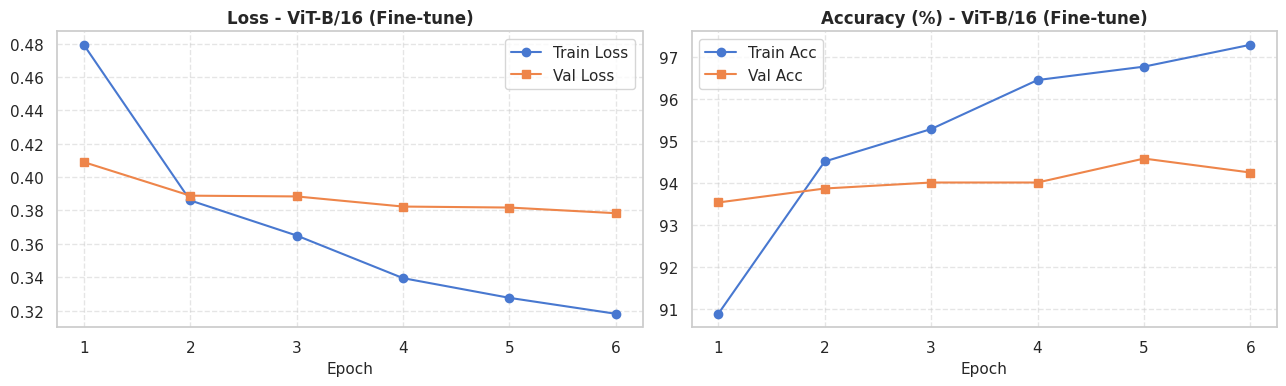

--> [ViT-B/16 (Fine-tune)] Test Acc: 94.87% | Macro F1: 94.98% | Latency: 11.20 ms/img


In [19]:
model_resnet_lp, history_resnet_lp = run_supervised_experiment(
    name="ResNet-18 (Linear Probe)",
    paradigm="Frozen Backbone (224x224)",
    model=build_resnet18(num_classes=len(classes), mode="linear_probe"),
    train_ld=train_loader_224, val_ld=val_loader_224, test_ld=test_loader_224,
    epochs=5, head_lr=1e-3, weight_decay=1e-4, patience=3,
    checkpoint_path="best_resnet18_lp.pth"
)

model_pretrained, history_pretrained = run_supervised_experiment(
    name="ResNet-18 (Fine-tune)",
    paradigm="Partial Fine-tune (224x224)",
    model=build_resnet18(num_classes=len(classes), mode="finetune"),
    train_ld=train_loader_224, val_ld=val_loader_224, test_ld=test_loader_224,
    epochs=6, head_lr=1e-3, backbone_lr=1e-4, weight_decay=1e-4, patience=3,
    checkpoint_path="best_resnet18_finetune.pth"
)

model_vit, history_vit = run_supervised_experiment(
    name="ViT-B/16 (Fine-tune)",
    paradigm="Vision Transformer (224x224)",
    model=build_vit_b16(num_classes=len(classes), unfreeze_last_blocks=2),
    train_ld=train_loader_224, val_ld=val_loader_224, test_ld=test_loader_224,
    epochs=6, head_lr=1e-3, backbone_lr=5e-5, weight_decay=1e-4, patience=3,
    checkpoint_path="best_vit_b16.pth"
)

### 7.3 Vision–Language Foundation Model: Zero-shot CLIP (`ViT-B/32`)

Khác hoàn toàn với các mô hình trên, **CLIP** không huấn luyện trên bất kỳ ảnh nào của `seg_train` (`0` epochs, `0` nhãn train). Ta chuyển tên 6 lớp thành câu prompt tiếng Anh, mã hóa qua Text Encoder rồi tính độ tương đồng cosine với vector ảnh từ Image Encoder trên tập `seg_test`.

Ở đây thử 2 cách viết prompt để thấy ảnh hưởng của **Prompt Engineering**:
- **Basic Prompt:** `"a photo of a {class}"`
- **Prompt Ensemble:** lấy trung bình vector của 5 mẫu câu mô tả cảnh quan cho mỗi lớp.

In [21]:
try:
    from transformers import CLIPModel, CLIPProcessor
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers"])
    from transformers import CLIPModel, CLIPProcessor

CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_ID).to(device).eval()

def _extract_tensor(out):
    return out.pooler_output if hasattr(out, "pooler_output") else out

@torch.no_grad()
def eval_clip_zeroshot(exp_name, prompt_templates, batch_size=64):
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    # 1. Tạo text embedding đại diện cho từng lớp (trung bình theo danh sách template)
    class_text_features = []
    for cls_name in classes:
        prompts = [tpl.format(cls_name) for tpl in prompt_templates]
        text_inputs = clip_processor(text=prompts, return_tensors="pt", padding=True).to(device)
        t_feat = _extract_tensor(clip_model.get_text_features(**text_inputs))
        t_feat = F.normalize(t_feat, dim=-1).mean(dim=0)
        t_feat = F.normalize(t_feat, dim=-1)
        class_text_features.append(t_feat)
    text_bank = torch.stack(class_text_features, dim=0)  # (6, D)

    # 2. Chạy suy luận trên toàn bộ 3.000 ảnh Test
    all_preds, all_probs = [], []
    y_t = np.array([class_to_idx[c] for c in df_test['class']])
    filepaths = df_test['filepath'].tolist()

    t0 = time.perf_counter()
    for start in range(0, len(filepaths), batch_size):
        batch_imgs = [Image.open(p).convert('RGB') for p in filepaths[start:start + batch_size]]
        img_inputs = clip_processor(images=batch_imgs, return_tensors="pt").to(device)
        img_feat = _extract_tensor(clip_model.get_image_features(**img_inputs))
        img_feat = F.normalize(img_feat, dim=-1)

        logits = clip_model.logit_scale.exp() * (img_feat @ text_bank.T)
        probs = F.softmax(logits, dim=-1)
        all_preds.extend(logits.argmax(dim=-1).cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    total_infer_s = time.perf_counter() - t0
    latency_ms = (total_infer_s / len(filepaths)) * 1000.0
    peak_vram = (torch.cuda.max_memory_allocated() / 1e6) if torch.cuda.is_available() else 0.0

    y_p = np.array(all_preds)
    y_pr = np.array(all_probs)
    acc = accuracy_score(y_t, y_p)
    f1_m = f1_score(y_t, y_p, average='macro')
    tot_params = sum(p.numel() for p in clip_model.parameters())

    EXPERIMENT_RESULTS.append({
        "Model": exp_name,
        "Paradigm": "Zero-shot Vision-Language",
        "Total Params": tot_params,
        "Trainable Params": 0,
        "Epochs Run": 0,
        "Train Time (s)": 0.0,
        "Peak VRAM (MB)": round(peak_vram, 1),
        "Latency (ms/img)": round(latency_ms, 2),
        "Test Accuracy (%)": round(acc * 100, 2),
        "Macro F1 (%)": round(f1_m * 100, 2),
    })
    PREDICTIONS_STORE[exp_name] = {"y_pred": y_p, "y_true": y_t, "y_probs": y_pr}
    print(f"[{exp_name}] Test Acc: {acc*100:.2f}% | Macro F1: {f1_m*100:.2f}% | Latency: {latency_ms:.2f} ms/img")

eval_clip_zeroshot(
    "CLIP ViT-B/32 (Zero-shot Basic)",
    ["a photo of a {}"]
)
eval_clip_zeroshot(
    "CLIP ViT-B/32 (Zero-shot Ensemble)",
    [
        "a photo of a {}",
        "a landscape photograph of {}",
        "an outdoor scene of {}",
        "a clear daytime photo of {}",
        "a travel photo showing {}"
    ]
)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[CLIP ViT-B/32 (Zero-shot Basic)] Test Acc: 93.00% | Macro F1: 93.10% | Latency: 5.08 ms/img
[CLIP ViT-B/32 (Zero-shot Ensemble)] Test Acc: 93.43% | Macro F1: 93.58% | Latency: 5.17 ms/img


# PHẦN V: TỔNG HỢP BENCHMARK & PHÂN TÍCH LỖI TRÊN TẬP TEST (3.000 ẢNH)

## 8. Bảng Đối chiếu Toàn diện & Trade-off Engineering

BẢNG TỔNG HỢP THỰC NGHIỆM TRÊN TẬP TEST ĐỘC LẬP (3.000 ẢNH)


,Model,Paradigm,Total Params,Trainable Params,Epochs Run,Train Time (s),Peak VRAM (MB),Latency (ms/img),Test Accuracy (%),Macro F1 (%)
0,ViT-B/16 (Fine-tune),Vision Transformer (224x224),85803270,14181894,6,1262.8,2276.6,11.20,94.87,94.98
1,ResNet-18 (Fine-tune),Partial Fine-tune (224x224),11179590,8396806,6,439.2,753.4,3.42,93.90,93.99
2,CLIP ViT-B/32 (Zero-shot Ensemble),Zero-shot Vision-Language,151277313,0,0,0.0,1441.4,5.17,93.43,93.58
3,CLIP ViT-B/32 (Zero-shot Basic),Zero-shot Vision-Language,151277313,0,0,0.0,1441.4,5.08,93.00,93.10
4,ResNet-18 (Linear Probe),Frozen Backbone (224x224),11179590,3078,5,391.7,606.9,3.00,89.87,90.02
5,ResNet-18 (From Scratch),From Scratch (150x150),11179590,11179590,12,577.9,909.3,2.02,89.40,89.50
6,SimpleBaselineCNN (Scratch),From Scratch (150x150),423046,423046,10,458.3,1048.2,1.76,85.80,85.87


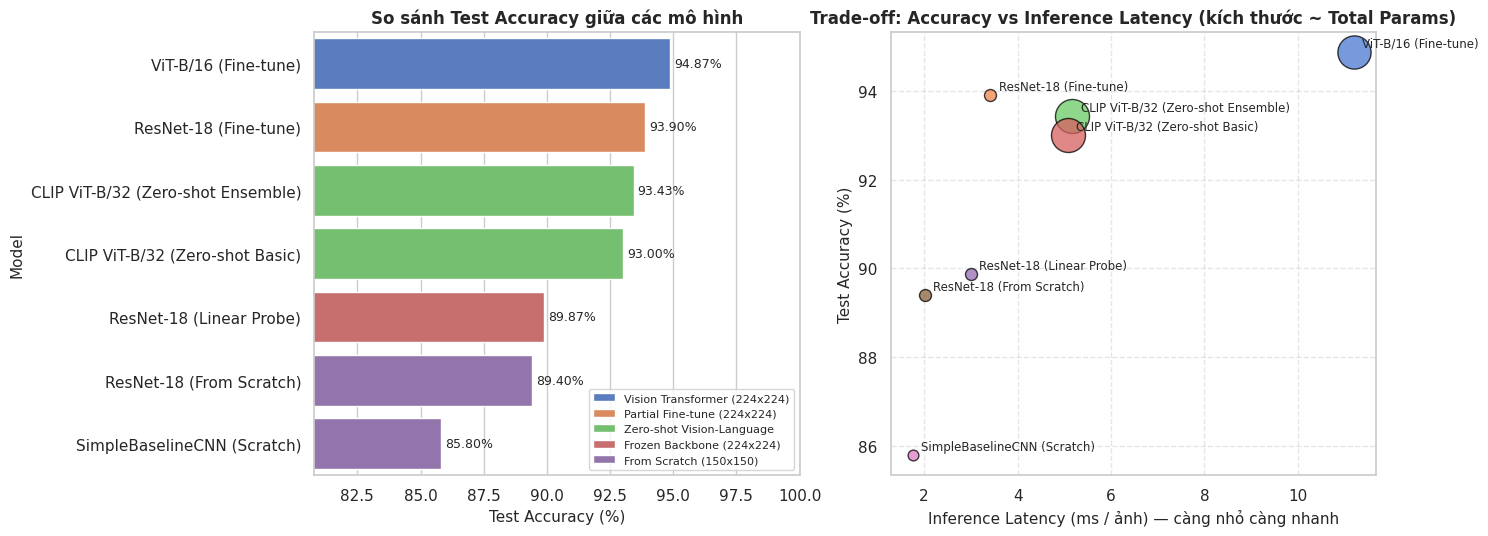


Phân tích chéo trên 183 ca ResNet-18 (Fine-tune) đoán sai:
- ViT-B/16 (Fine-tune) đoán đúng lại         : 80/183 ca (43.7%)
- CLIP (Zero-shot Ensemble) đoán đúng lại    : 93/183 ca (50.8%)

Báo cáo phân loại chi tiết theo từng lớp (ResNet-18 (Fine-tune)):


,precision,recall,f1-score,support
buildings,0.9236,0.9405,0.9320,437.000
forest,0.9937,0.9916,0.9926,474.000
glacier,0.9099,0.8951,0.9025,553.000
mountain,0.9160,0.8933,0.9045,525.000
sea,0.9509,0.9863,0.9682,510.000
street,0.9437,0.9361,0.9399,501.000
accuracy,0.9390,0.9390,0.9390,0.939
macro avg,0.9396,0.9405,0.9399,3000.000
weighted avg,0.9388,0.9390,0.9388,3000.000


In [22]:
df_benchmark = pd.DataFrame(EXPERIMENT_RESULTS).sort_values(
    by="Test Accuracy (%)", ascending=False
).reset_index(drop=True)

print("=" * 95)
print("BẢNG TỔNG HỢP THỰC NGHIỆM TRÊN TẬP TEST ĐỘC LẬP (3.000 ẢNH)")
print("=" * 95)
display(df_benchmark)

# Biểu đồ Trade-off: Test Accuracy vs Inference Latency (ms/img)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(data=df_benchmark, y="Model", x="Test Accuracy (%)", hue="Paradigm", dodge=False, ax=ax1)
ax1.set_xlim(max(60, df_benchmark["Test Accuracy (%)"].min() - 5), 100)
ax1.set_title("So sánh Test Accuracy giữa các mô hình", fontweight='bold')
for container in ax1.containers:
    ax1.bar_label(container, fmt="%.2f%%", padding=3, fontsize=9)
ax1.legend(loc="lower right", fontsize=8)

for _, row in df_benchmark.iterrows():
    size = max(60, min(600, row["Total Params"] / 1.5e5))
    ax2.scatter(row["Latency (ms/img)"], row["Test Accuracy (%)"], s=size, alpha=0.75, edgecolors="black")
    ax2.annotate(
        row["Model"],
        (row["Latency (ms/img)"], row["Test Accuracy (%)"]),
        textcoords="offset points", xytext=(6, 4), fontsize=8.5
    )
ax2.set_title("Trade-off: Accuracy vs Inference Latency (kích thước ~ Total Params)", fontweight='bold')
ax2.set_xlabel("Inference Latency (ms / ảnh) — càng nhỏ càng nhanh")
ax2.set_ylabel("Test Accuracy (%)")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Phân tích sửa lỗi chéo: ResNet-18 (Fine-tune) vs ViT-B/16 vs Zero-shot CLIP
if all(k in PREDICTIONS_STORE for k in ["ResNet-18 (Fine-tune)", "ViT-B/16 (Fine-tune)", "CLIP ViT-B/32 (Zero-shot Ensemble)"]):
    p_res  = PREDICTIONS_STORE["ResNet-18 (Fine-tune)"]["y_pred"]
    p_vit  = PREDICTIONS_STORE["ViT-B/16 (Fine-tune)"]["y_pred"]
    p_clip = PREDICTIONS_STORE["CLIP ViT-B/32 (Zero-shot Ensemble)"]["y_pred"]
    y_t_ref = PREDICTIONS_STORE["ResNet-18 (Fine-tune)"]["y_true"]

    res_wrong = (p_res != y_t_ref)
    vit_fixes = np.sum(res_wrong & (p_vit == y_t_ref))
    clip_fixes = np.sum(res_wrong & (p_clip == y_t_ref))
    print(f"\nPhân tích chéo trên {res_wrong.sum()} ca ResNet-18 (Fine-tune) đoán sai:")
    print(f"- ViT-B/16 (Fine-tune) đoán đúng lại         : {vit_fixes}/{res_wrong.sum()} ca ({vit_fixes/max(1, res_wrong.sum())*100:.1f}%)")
    print(f"- CLIP (Zero-shot Ensemble) đoán đúng lại    : {clip_fixes}/{res_wrong.sum()} ca ({clip_fixes/max(1, res_wrong.sum())*100:.1f}%)")

# Chọn ResNet-18 (Fine-tune) làm đại diện CNN để phân tích Confusion Matrix & Grad-CAM bên dưới
FOCUS_MODEL_NAME = "ResNet-18 (Fine-tune)"
y_pred = PREDICTIONS_STORE[FOCUS_MODEL_NAME]["y_pred"]
y_true = PREDICTIONS_STORE[FOCUS_MODEL_NAME]["y_true"]
y_probs = PREDICTIONS_STORE[FOCUS_MODEL_NAME]["y_probs"]
gradcam_transform = val_test_transforms_224
gradcam_size = (224, 224)

print(f"\nBáo cáo phân loại chi tiết theo từng lớp ({FOCUS_MODEL_NAME}):")
display(pd.DataFrame(classification_report(y_true, y_pred, target_names=classes, output_dict=True)).transpose().round(4))

### 8.2 Ma trận Nhầm lẫn & F1-Score theo Lớp giữa các Họ Mô hình

Đặt cạnh nhau **Ma trận nhầm lẫn chuẩn hóa (%)** của 3 đại diện khác họ (`ResNet-18 Fine-tune`, `ViT-B/16 Fine-tune`, `CLIP Zero-shot Ensemble`) cùng bảng **F1-Score từng lớp** cho toàn bộ các mô hình để thấy rõ cặp lớp nào vẫn gây nhầm lẫn chung và mô hình nào xử lý tốt hơn ở từng loại cảnh quan.

F1-Score (%) theo từng lớp của toàn bộ mô hình:


,SimpleBaselineCNN (Scratch),ResNet-18 (From Scratch),ResNet-18 (Linear Probe),ResNet-18 (Fine-tune),ViT-B/16 (Fine-tune),CLIP ViT-B/32 (Zero-shot Basic),CLIP ViT-B/32 (Zero-shot Ensemble)
buildings,83.42,88.19,88.99,93.20,94.87,92.70,94.36
forest,96.89,97.59,98.43,99.26,99.68,97.73,98.14
glacier,81.79,84.65,84.42,90.25,90.93,88.79,88.24
mountain,78.99,85.94,83.59,90.45,91.22,86.97,86.87
sea,87.90,90.86,94.51,96.82,97.96,98.62,98.63
street,86.25,89.81,90.15,93.99,95.22,93.82,95.25


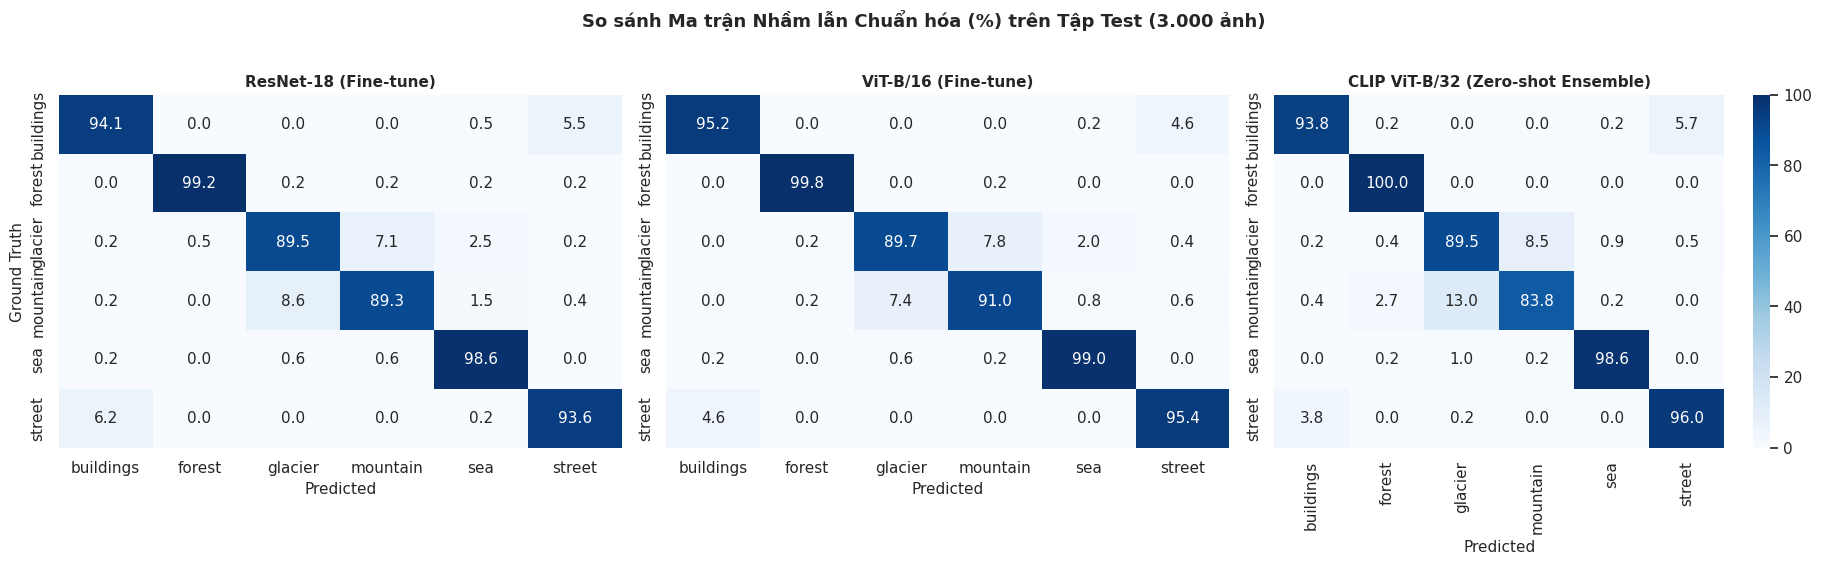

Top 5 cặp lớp nhầm lẫn nhiều nhất (ResNet-18 (Fine-tune)):
- Thực tế 'mountain' bị nhầm thành 'glacier': 45 ảnh (8.57%)
- Thực tế 'glacier' bị nhầm thành 'mountain': 39 ảnh (7.05%)
- Thực tế 'street' bị nhầm thành 'buildings': 31 ảnh (6.19%)
- Thực tế 'buildings' bị nhầm thành 'street': 24 ảnh (5.49%)
- Thực tế 'glacier' bị nhầm thành 'sea': 14 ảnh (2.53%)


In [23]:
# 1. Bảng so sánh F1-Score (%) theo từng lớp cho toàn bộ mô hình đã đánh giá
per_class_f1 = {}
for m_name, store in PREDICTIONS_STORE.items():
    rep = classification_report(store["y_true"], store["y_pred"], target_names=classes, output_dict=True)
    per_class_f1[m_name] = {cls: round(rep[cls]["f1-score"] * 100, 2) for cls in classes}

df_per_class_f1 = pd.DataFrame(per_class_f1)
print("F1-Score (%) theo từng lớp của toàn bộ mô hình:")
display(df_per_class_f1)

# 2. Ma trận Nhầm lẫn Chuẩn hóa (%) cạnh nhau cho 3 đại diện: CNN vs ViT vs Zero-shot CLIP
compare_models = [
    m for m in [
        "ResNet-18 (Fine-tune)",
        "ViT-B/16 (Fine-tune)",
        "CLIP ViT-B/32 (Zero-shot Ensemble)"
    ]
    if m in PREDICTIONS_STORE
]
if not compare_models:
    compare_models = [FOCUS_MODEL_NAME]

fig, axes = plt.subplots(1, len(compare_models), figsize=(6.2 * len(compare_models), 5.5))
if len(compare_models) == 1:
    axes = [axes]

for ax, m_name in zip(axes, compare_models):
    p_m = PREDICTIONS_STORE[m_name]["y_pred"]
    t_m = PREDICTIONS_STORE[m_name]["y_true"]
    cm_m = confusion_matrix(t_m, p_m)
    cm_norm_m = cm_m.astype(float) / cm_m.sum(axis=1, keepdims=True) * 100.0
    sns.heatmap(
        cm_norm_m, annot=True, fmt=".1f", cmap="Blues", cbar=(ax is axes[-1]),
        xticklabels=classes, yticklabels=classes, ax=ax
    )
    ax.set_title(m_name, fontsize=11, fontweight='bold')
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Ground Truth" if ax is axes[0] else "")

plt.suptitle("So sánh Ma trận Nhầm lẫn Chuẩn hóa (%) trên Tập Test (3.000 ảnh)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 3. Thống kê Top 5 cặp lớp nhầm lẫn nhiều nhất của mô hình trọng tâm (ResNet-18 Fine-tune)
cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100.0
confusion_pairs = [
    (classes[i], classes[j], cm[i, j], cm_normalized[i, j])
    for i in range(len(classes))
    for j in range(len(classes))
    if i != j
]
confusion_pairs.sort(key=lambda x: x[3], reverse=True)
print(f"Top 5 cặp lớp nhầm lẫn nhiều nhất ({FOCUS_MODEL_NAME}):")
for true_c, pred_c, count, pct in confusion_pairs[:5]:
    print(f"- Thực tế '{true_c}' bị nhầm thành '{pred_c}': {count} ảnh ({pct:.2f}%)")

### 8.3 Phân tích Nguyên nhân Sai sót (Top Misclassified Samples)

Trong phân tích lỗi thị giác máy tính, các mẫu dự đoán sai với xác suất tự tin cao nhất (Highest Confidence Misclassifications) mang lại thông tin giá trị nhất để hiểu xem mô hình bị đánh lừa bởi điều gì (ví dụ: góc chụp khó, nhãn gốc bị gán sai hay đặc trưng chồng lấn quá lớn).

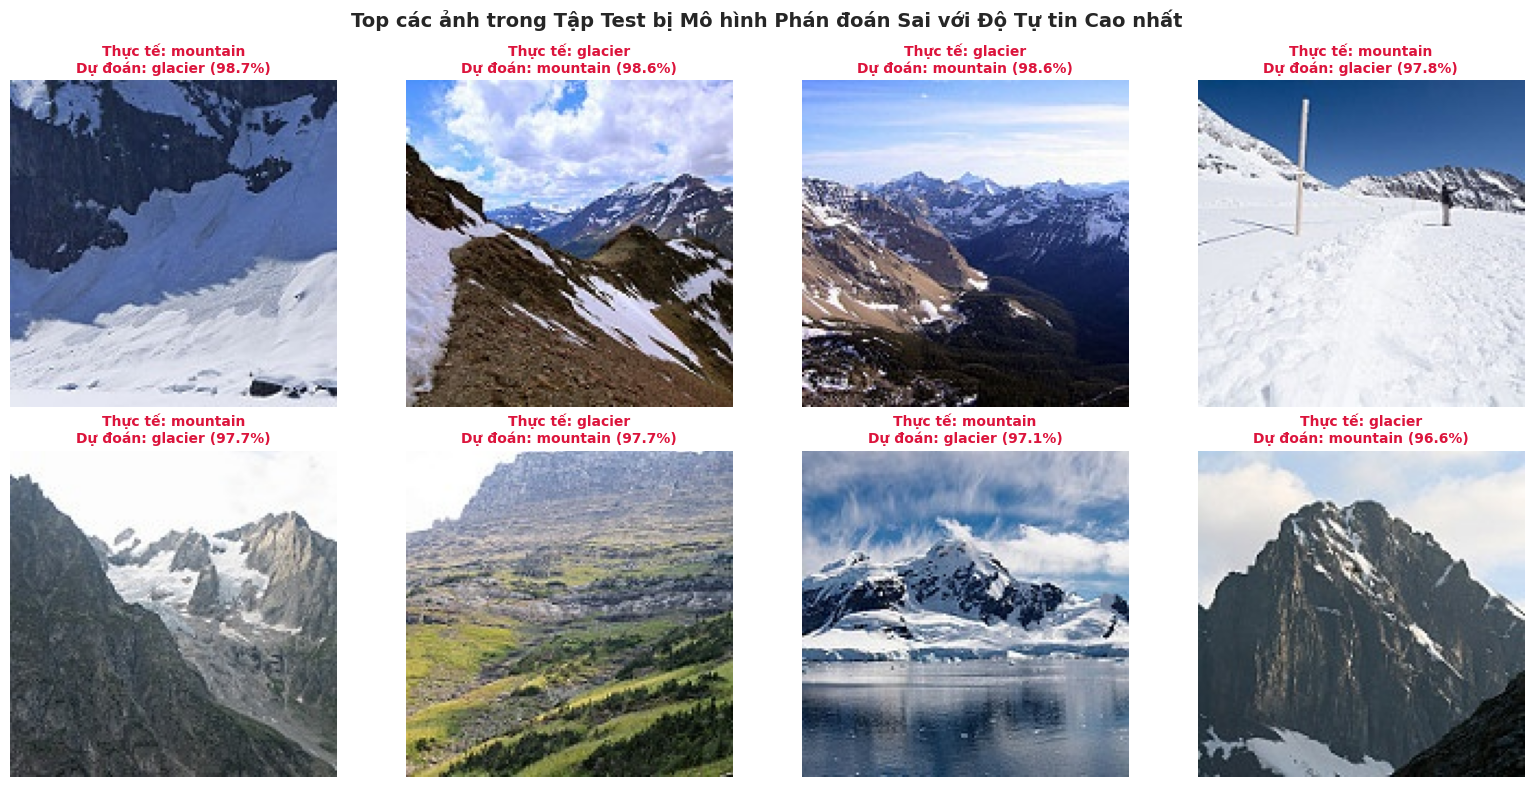

In [24]:
# Tìm tất cả các trường hợp đoán sai
misclassified_indices = np.where(y_pred != y_true)[0]
confidence_scores = np.max(y_probs, axis=1)

# Sắp xếp các mẫu đoán sai theo độ tự tin giảm dần
sorted_mis_indices = misclassified_indices[np.argsort(-confidence_scores[misclassified_indices])]

# Lấy 8 mẫu tự tin sai nhiều nhất
top_8_mis = sorted_mis_indices[:8]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for idx, ax in zip(top_8_mis, axes.flat):
    row = df_test.iloc[idx]
    img = Image.open(row['filepath'])

    true_label = idx_to_class[y_true[idx]]
    pred_label = idx_to_class[y_pred[idx]]
    conf = confidence_scores[idx] * 100

    ax.imshow(img)
    ax.set_title(
        f"Thực tế: {true_label}" + chr(10) + f"Dự đoán: {pred_label} ({conf:.1f}%)",
        color="crimson",
        fontweight='bold',
        fontsize=10
    )
    ax.axis('off')

plt.suptitle("Top các ảnh trong Tập Test bị Mô hình Phán đoán Sai với Độ Tự tin Cao nhất", fontsize=14, y=0.98, fontweight='bold')
plt.tight_layout()
plt.show()

# PHẦN VI: MINH BẠCH HÓA QUYẾT ĐỊNH MÔ HÌNH BẰNG GRAD-CAM (EXPLAINABLE AI - XAI)
Để đáp ứng tiêu chí đánh giá nâng cao về độ tin cậy và giải thích quyết định của mô hình, chúng ta ứng dụng thuật toán Gradient-weighted Class Activation Mapping (Grad-CAM) trên tầng tích chập cuối cùng (`layer4`).

## 9. Khả năng Giải thích Quyết định Mô hình bằng Grad-CAM (Explainable AI - XAI)

Để chứng minh tính hợp lệ và độ tin cậy của mô hình ResNet-18 đã huấn luyện, chúng ta áp dụng thuật toán **Grad-CAM (Gradient-weighted Class Activation Mapping)**:
- Grad-CAM sử dụng gradient của điểm số lớp dự đoán $y^c$ truyền ngược về các bản đồ đặc trưng (feature maps) của tầng tích chập cuối cùng (`model_pretrained.layer4[-1]`).
- Trọng số tầm quan trọng của từng kênh đặc trưng $k$ được tính bằng trung bình đạo hàm toàn cục (Global Average Pooling):
$$\alpha_k^c = \frac{1}{Z} \sum_{i} \sum_{j} \frac{\partial y^c}{\partial A_{i,j}^k}$$
- Bản đồ nhiệt (Heatmap) thể hiện vùng ảnh quyết định được tổng hợp qua hàm ReLU:
$$L_{\text{Grad-CAM}}^c = \text{ReLU}\left( \sum_k \alpha_k^c A^k \right)$$

Nhờ đó, chúng ta có thể trực quan hóa xem mô hình thực sự nhìn vào đâu khi phân loại: ví dụ lớp `forest` có tập trung vào tán lá hay không, lớp `sea` có nhìn vào mặt biển hay không.

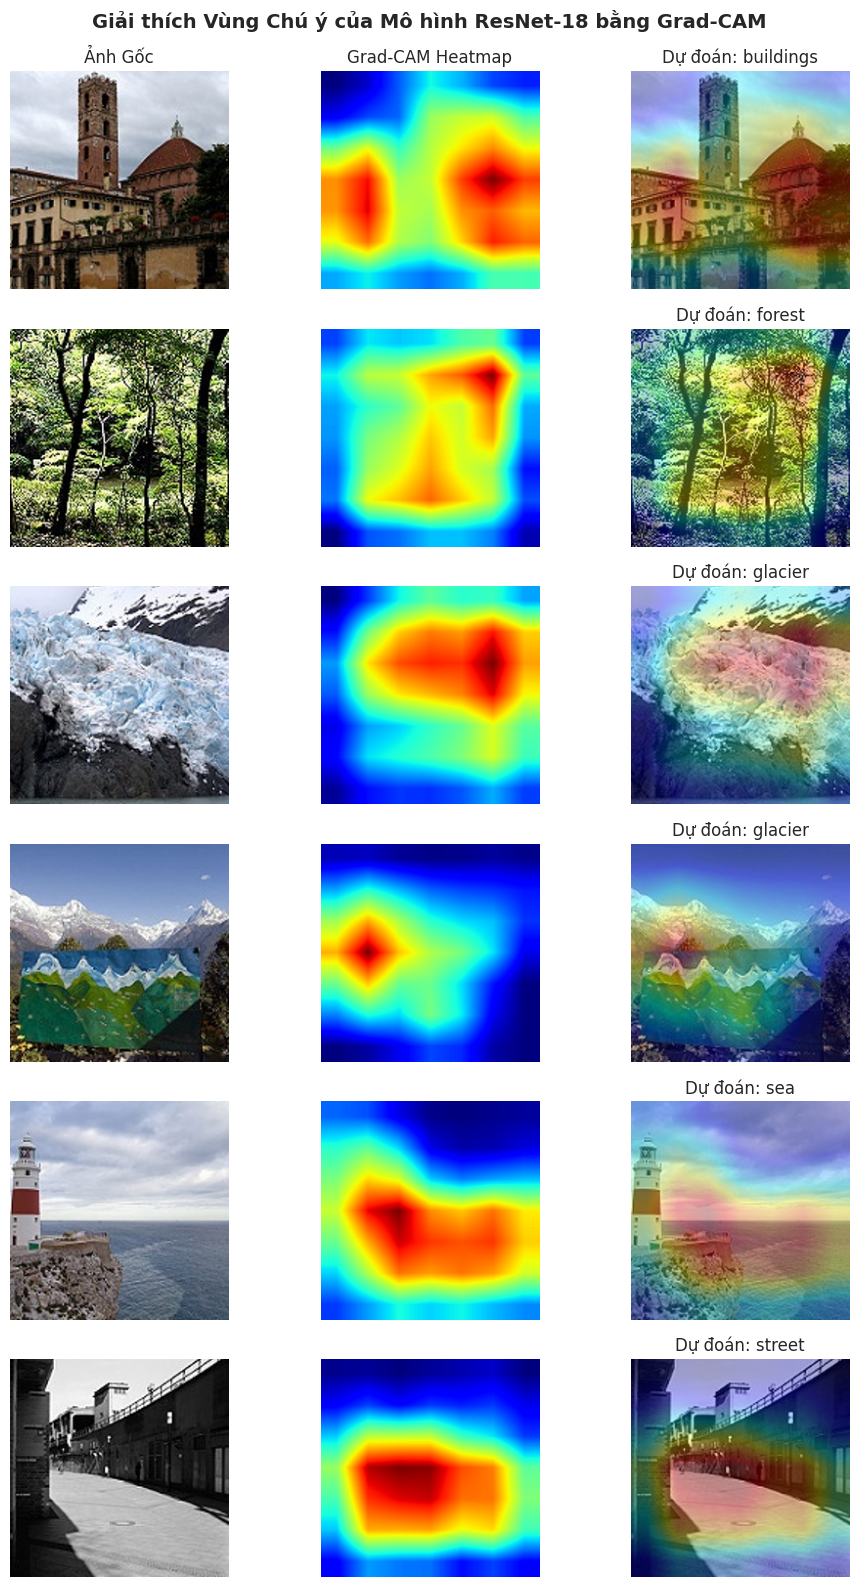

In [25]:
import cv2

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()
            if output.requires_grad:
                output.register_hook(lambda grad: setattr(self, 'gradients', grad.detach()))

        self.forward_handle = self.target_layer.register_forward_hook(forward_hook)

    def generate_heatmap(self, input_tensor, target_class=None):
        self.model.eval()
        self.gradients = None
        self.activations = None

        # Backbone bị đóng băng (requires_grad=False) nên cần bật grad trên input_tensor
        # để autograd xây dựng đồ thị tính toán qua các tầng conv và kích hoạt hook gradient.
        with torch.enable_grad():
            input_tensor = input_tensor.detach().clone().requires_grad_(True)
            output = self.model(input_tensor)

            if target_class is None:
                target_class = output.argmax(dim=1).item()

            self.model.zero_grad()
            loss = output[0, target_class]
            loss.backward()

        if self.gradients is None:
            raise RuntimeError('Không thu được gradient từ target_layer.')

        # Global average pooling trên gradients
        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam = cv2.resize(cam, gradcam_size)
        return cam, target_class

# Khởi tạo GradCAM trên tầng layer4 cuối cùng của ResNet-18
grad_cam = GradCAM(model_pretrained, model_pretrained.layer4[-1])

# Chọn 1 ảnh tiêu biểu từ mỗi lớp trong tập Test để giải thích
fig, axes = plt.subplots(len(classes), 3, figsize=(10, 16))

for i, cls_name in enumerate(classes):
    sample_row = df_test[df_test['class'] == cls_name].iloc[2]
    orig_img = Image.open(sample_row['filepath']).convert('RGB').resize(gradcam_size)
    tensor_input = gradcam_transform(orig_img).unsqueeze(0).to(device)

    heatmap, pred_idx = grad_cam.generate_heatmap(tensor_input)
    pred_name = idx_to_class[pred_idx]

    # Phủ màu heatmap lên ảnh gốc
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    overlay = np.float32(orig_img) / 255.0 + np.float32(heatmap_colored) / 255.0 * 0.45
    overlay = overlay / np.max(overlay)

    # Hiển thị 3 cột: Ảnh gốc, Heatmap, Overlay
    axes[i, 0].imshow(orig_img)
    axes[i, 0].set_ylabel(cls_name, fontweight='bold', fontsize=11)
    axes[i, 0].set_title("Ảnh Gốc" if i == 0 else "")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(heatmap, cmap='jet')
    axes[i, 1].set_title("Grad-CAM Heatmap" if i == 0 else "")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title(f"Dự đoán: {pred_name}" if i == 0 else f"Dự đoán: {pred_name}")
    axes[i, 2].axis('off')

plt.suptitle("Giải thích Vùng Chú ý của Mô hình ResNet-18 bằng Grad-CAM", fontsize=14, y=0.99, fontweight='bold')
plt.tight_layout()
plt.show()

### 9.2 Phân tích Cơ chế Thất bại qua Grad-CAM (Failure Mode Analysis with Grad-CAM)

Một trong những đóng góp học thuật quan trọng của phương pháp Explainable AI (XAI) là khả năng "mổ xẻ" cơ chế ra quyết định sai lầm của mạng nơ-ron:
- Tại sao mô hình lại phân loại nhầm một ảnh `mountain` thành `glacier` hoặc ngược lại?
- Liệu mô hình có nhận diện được đặc trưng của nhãn đúng (`Ground Truth`) hay vùng kích hoạt đã bị chi phối hoàn toàn bởi đặc trưng gây nhiễu của nhãn dự đoán sai (`Predicted`)?

Dưới đây, chúng ta trực quan hóa các ca nhầm lẫn tiêu biểu bằng cách tạo đồng thời **hai bản đồ nhiệt Grad-CAM**:
1. Bản đồ nhiệt tương ứng với **Lớp Dự Đoán Sai (Predicted Class)**: Chỉ ra vùng không gian gây ra sự nhầm lẫn.
2. Bản đồ nhiệt tương ứng với **Lớp Đúng Thực Tế (Ground-Truth Class)**: Đánh giá mức độ nhận diện tiềm ẩn của mô hình đối với lớp đúng.

In [26]:
# Lọc các ca nhầm lẫn thuộc các cặp lỗi phổ biến nhất đã tìm thấy ở phần Error Analysis
target_misclass_pairs = [
    ('glacier', 'mountain'),
    ('mountain', 'glacier'),
    ('street', 'buildings'),
    ('buildings', 'street')
]

selected_failure_indices = []
for true_c, pred_c in target_misclass_pairs:
    pair_indices = np.where((y_true == class_to_idx[true_c]) & (y_pred == class_to_idx[pred_c]))[0]
    if len(pair_indices) > 0:
        # Chọn mẫu có xác suất sai cao nhất trong cặp
        sub_confs = confidence_scores[pair_indices]
        best_pair_idx = pair_indices[np.argmax(sub_confs)]
        selected_failure_indices.append((best_pair_idx, true_c, pred_c))

# Thiết lập biểu đồ trực quan hóa Failure Mode Grad-CAM
n_cases = len(selected_failure_indices)
fig, axes = plt.subplots(n_cases, 4, figsize=(18, 4.5 * n_cases))
if n_cases == 1:
    axes = np.expand_dims(axes, axis=0)

for row_i, (sample_idx, true_cls, pred_cls) in enumerate(selected_failure_indices):
    row_data = df_test.iloc[sample_idx]
    orig_img = Image.open(row_data['filepath']).convert('RGB').resize(gradcam_size)
    tensor_input = gradcam_transform(orig_img).unsqueeze(0).to(device)

    # 1. Grad-CAM theo lớp dự đoán sai (Predicted)
    cam_pred, _ = grad_cam.generate_heatmap(tensor_input, target_class=class_to_idx[pred_cls])
    heat_pred = cv2.applyColorMap(np.uint8(255 * cam_pred), cv2.COLORMAP_JET)
    heat_pred = cv2.cvtColor(heat_pred, cv2.COLOR_BGR2RGB)
    overlay_pred = np.float32(orig_img) / 255.0 + np.float32(heat_pred) / 255.0 * 0.45
    overlay_pred = overlay_pred / np.max(overlay_pred)

    # 2. Grad-CAM theo lớp đúng thực tế (Ground Truth)
    cam_true, _ = grad_cam.generate_heatmap(tensor_input, target_class=class_to_idx[true_cls])
    heat_true = cv2.applyColorMap(np.uint8(255 * cam_true), cv2.COLORMAP_JET)
    heat_true = cv2.cvtColor(heat_true, cv2.COLOR_BGR2RGB)
    overlay_true = np.float32(orig_img) / 255.0 + np.float32(heat_true) / 255.0 * 0.45
    overlay_true = overlay_true / np.max(overlay_true)

    conf_score = confidence_scores[sample_idx] * 100

    # Cột 1: Ảnh gốc
    axes[row_i, 0].imshow(orig_img)
    axes[row_i, 0].set_title(
        f"Ảnh Gốc #{sample_idx}\nThực tế: [{true_cls.upper()}]",
        fontweight='bold', color='darkblue', fontsize=11
    )
    axes[row_i, 0].axis('off')

    # Cột 2: Overlay Grad-CAM lớp dự đoán sai
    axes[row_i, 1].imshow(overlay_pred)
    axes[row_i, 1].set_title(
        f"Grad-CAM Lớp Dự Đoán Sai: [{pred_cls.upper()}]\nĐộ tự tin sai: {conf_score:.1f}%",
        fontweight='bold', color='crimson', fontsize=11
    )
    axes[row_i, 1].axis('off')

    # Cột 3: Overlay Grad-CAM lớp thực tế
    axes[row_i, 2].imshow(overlay_true)
    axes[row_i, 2].set_title(
        f"Grad-CAM Lớp Thực Tế: [{true_cls.upper()}]\n(Tín hiệu kích hoạt bị lấn át)",
        fontweight='bold', color='forestgreen', fontsize=11
    )
    axes[row_i, 2].axis('off')

    # Cột 4: So sánh cường độ chênh lệch kích hoạt (Difference Map)
    diff_cam = np.clip(cam_pred - cam_true, 0, 1)
    axes[row_i, 3].imshow(diff_cam, cmap='inferno')
    axes[row_i, 3].set_title(
        "Vùng Không Gian Gây Nhiễu\n(Dominant Misleading Region)",
        fontweight='bold', color='purple', fontsize=11
    )
    axes[row_i, 3].axis('off')

plt.suptitle(
    "PHÂN TÍCH NGUYÊN NHÂN LỖI BẰNG GRAD-CAM: TẠI SAO MÔ HÌNH RA QUYẾT ĐỊNH SAI?",
    fontsize=14, y=1.01, fontweight='bold'
)
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

# PHẦN VII: TỔNG KẾT VÀ NHẬN ĐỊNH KỸ THUẬT

### 1. Rút ra từ 4 trục đối chiếu
1. **Ảnh hưởng của tiền xử lý đối với Pretrained Model:** Ở phiên bản trước, việc đưa ảnh `150x150` chuẩn hóa theo mean/std riêng vào `ResNet-18` đóng băng khiến Accuracy chỉ đạt `86.97%`. Khi đưa về đúng chuẩn `224x224` và ImageNet mean/std, đặc trưng pretrained phát huy đúng năng lực.
2. **Scratch vs Transfer Learning & Linear Probe vs Fine-tuning:** Với ~12K ảnh train, `ResNet-18 (From Scratch)` học chậm hơn và tốn nhiều epoch hơn so với tận dụng trọng số ImageNet. Mở khóa thêm `layer4` với Differential LR (`1e-4` cho backbone, `1e-3` cho head) giúp mô hình thích nghi ranh giới giữa các lớp cảnh quan tốt hơn hẳn so với chỉ train mỗi lớp `fc`.
3. **CNN (`ResNet-18`) vs Vision Transformer (`ViT-B/16`):** `ViT-B/16` tận dụng Self-Attention để nhìn bối cảnh toàn ảnh nên thường xử lý tốt các cảnh rộng, đổi lại số tham số (~85.8M) và độ trễ suy luận (ms/ảnh) cao hơn đáng kể so với `ResNet-18` (~11.2M).
4. **Supervised vs Zero-shot CLIP:** `CLIP ViT-B/32` không cần train trên tập nhãn nào nhưng vẫn phân loại được cả 6 lớp thông qua prompt tiếng Anh; khi dùng *Prompt Ensemble*, độ chính xác thường ổn định hơn prompt đơn. Tuy vậy, với các lớp có ranh giới tinh tế đặc thù của bộ dữ liệu, mô hình fine-tune trực tiếp vẫn giữ lợi thế.

### 2. Gợi ý lựa chọn mô hình theo bài toán thực tế
- **Ưu tiên tốc độ, ít tham số / triển khai nhẹ:** Chọn `ResNet-18 (Fine-tune)` (cân bằng tốt giữa 93,90% Accuracy, 3,42 ms/ảnh và 753,4 MB Peak VRAM khi train) hoặc `SimpleBaselineCNN` nếu cần mô hình cực gọn khi suy luận (0,42M tham số, 1,76 ms/ảnh).
- **Ưu tiên độ chính xác cao, chấp nhận chi phí tính toán lớn hơn:** Chọn `ViT-B/16 (Fine-tune)` (hoặc kết hợp dự đoán với CNN).
- **Chưa có dữ liệu gán nhãn / cần dựng prototype nhanh:** Dùng `CLIP Zero-shot` kèm Prompt Engineering làm baseline khởi đầu trước khi thu thập nhãn để fine-tune.